# IMF Country Report → AI Pipeline → Financial Stability Dashboard

**Student ID:** 24120472
**Allocation:** Seychelles  
**Report used:** IMF Country Report No. 25/147 – *Seychelles: Fourth Reviews Under the Arrangement Under the Extended Fund Facility and the Arrangement Under the Resilience and Sustainability Facility* (June 2025)

This project analyses the latest Seychelles IMF report used for the assignment. The report covers the fourth reviews under the Extended Fund Facility (EFF) and the Resilience and Sustainability Facility (RSF). It examines Seychelles' recent economic developments, macroeconomic outlook, financial stability, policy discussions, and structural reforms.

**How to run it:** Open the notebook in Google Colab and select **Runtime → Run all**. The following setup is required first:

1. **IMF report PDF:** Upload the Seychelles IMF report to Google Drive. The notebook uses the file path `/content/drive/MyDrive/Seychelles.pdf`.
2. **Gemini API key:** Save your Gemini API key in Google Colab Secrets under the name `GEMINI_API_KEY`.

The notebook processes the report and produces summaries, structured financial indicators, retrieval results, evaluation outputs, and dashboard visualisations. Generated outputs are saved using the output paths configured in the notebook.

| Section | What I do there |
|---|---|
| **0. Setup** | Import libraries, configure project settings, connect Google Drive, set up Gemini, and define reusable functions for language-model requests. |
| **Task 1 – PDF Processing and Summarisation** | Extract and clean the IMF PDF, divide the report into chunks and sections, generate section and executive summaries, and evaluate their consistency, completeness, and factual accuracy. |
| **Task 2 – Financial Stability Analysis** | Analyse seven financial-stability themes, extract economic strengths and vulnerabilities, create structured numerical indicator outputs, identify historical and projected trends, and validate the results. |
| **Task 3 – Retrieval-Augmented Generation (RAG)** | Create document embeddings, build FAISS indexes, retrieve relevant report passages, generate evidence-based answers, and evaluate retrieval and citation quality. |
| **Extension – Multi-Query RAG** | Generate alternative question formulations, combine retrieval results using reciprocal-rank fusion, and compare Multi-Query RAG with standard single-query retrieval. |
| **Task 4 – Visualisation and Dashboard** | Reshape data using `pd.melt`, create financial-stability charts, compare evaluation results, and produce the final Seychelles dashboard. |
| **Final Checks** | Run validation tests, record software versions, review generated files, and compile the final project outputs. |

**Project objective:** To develop an AI-assisted analytical pipeline that extracts, summarises, evaluates, and visualises information from the Seychelles IMF report, with particular attention to macroeconomic conditions and financial stability.

## 0. Setup

### 0.1 Libraries

I use `pypdf` to extract text from the Seychelles IMF PDF, `tiktoken` to count tokens when creating document chunks, and `google-genai` to access Gemini for summarisation, information extraction, question answering, and evaluation. For Task 3, I use `sentence-transformers` to generate text embeddings and `faiss-cpu` to build the vector search index used for semantic retrieval.

In [1]:
!pip install -q pypdf tiktoken google-genai sentence-transformers faiss-cpu

In [2]:
import os, re, sys, json, time, random, hashlib, unicodedata
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import tiktoken
from pypdf import PdfReader

pd.set_option("display.max_colwidth", 120)
print("Libraries loaded")

Libraries loaded


### 0.2 Configuration

I put the main project settings, file paths, model names, and processing parameters in one place so they can be changed easily without editing code throughout the notebook.

I use two groups of language models. The **extractor** generates summaries, extracts numerical and qualitative information, and answers the RAG evaluation questions. The **judge** independently evaluates the generated outputs for accuracy, completeness, and consistency with the Seychelles IMF report.

I keep the extractor and judge roles separate so that the judge does not evaluate its own answers. Each group also has backup models configured to handle API availability issues, including `429` and `503` errors. If one model fails, the next available model is tried. The notebook also records which model produced each output to support transparency and reproducibility.

In [3]:
IN_COLAB = "google.colab" in sys.modules

DRIVE_ROOT = "/content/drive/MyDrive" if IN_COLAB else os.path.abspath(".")
PDF_PATH   = os.path.join(DRIVE_ROOT, "seychelles")
OUT_DIR    = os.path.join(DRIVE_ROOT, "imf_outputs")
CACHE_DIR  = os.path.join(OUT_DIR, "cache")
FIG_DIR    = os.path.join(OUT_DIR, "figures")

COUNTRY = "Seychelles"

# LLM roles: extractor (summaries, extraction, RAG answers) vs judge (evaluation only)
EXTRACT_MODELS = ["gemini-3.5-flash", "gemini-3-flash-preview", "gemini-3.6-flash",
                  "gemini-3.7-flash", "gemini-3.8-flash", "gemini-flash-latest"]
JUDGE_MODELS   = ["gemini-3.5-flash-lite", "gemini-3.1-flash-lite"]
TEMPERATURE    = 0.0          # deterministic as possible -> reproducible + cache-friendly
MIN_GAP_S      = 4            # pause between API calls (free-tier rate limits)

In [4]:
# Chunking (brief suggests 300-500 tokens with ~50-token overlap)
CHUNK_TOKENS   = 350          # leaves head-room under BGE's 512-token limit (see Task 3)
CHUNK_OVERLAP  = 50

# Retrieval
EMBED_MODELS = {"MiniLM": "sentence-transformers/all-MiniLM-L6-v2",   # baseline
                "BGE":    "BAAI/bge-small-en-v1.5"}                   # chosen model
QUERY_PREFIX = {"MiniLM": "", "BGE": "Represent this sentence for searching relevant passages: "}
TOP_K   = 5                   # baseline context size
MQ_K    = 8                   # broader context for Multi-Query RAG (extension)
RRF_K   = 60                  # standard Reciprocal Rank Fusion constant
SEED    = 42

FALLBACK = -1.0               # value for an indicator the report does not state
print("Config ready")

Config ready


In [7]:
if IN_COLAB:
    from google.colab import drive, userdata
    drive.mount("/content/drive")

for d in (OUT_DIR, CACHE_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

PDF_PATH = os.path.join(DRIVE_ROOT, "Seychelles.pdf")

assert os.path.exists(PDF_PATH), f"PDF not found at {PDF_PATH}"

print("PDF found:", PDF_PATH)
print("Outputs  :", OUT_DIR)
print("Country  :", COUNTRY)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PDF found: /content/drive/MyDrive/Seychelles.pdf
Outputs  : /content/drive/MyDrive/imf_outputs
Country  : Seychelles


### 0.3 Gemini Client and Model Availability

The API key is read securely from Colab Secrets, so it is never written directly into the notebook. I then check which of my configured models are available with this API key before starting the main pipeline.

I added this check because `gemini-2.5-flash` returned a `404` error when I first started the project. Checking model availability at the beginning helps identify access or compatibility issues early, rather than discovering them halfway through a long run.

In [8]:
from google import genai
from google.genai import types

API_KEY = userdata.get("GEMINI_API_KEY") if IN_COLAB else os.environ.get("GEMINI_API_KEY")
client = genai.Client(api_key=API_KEY)

try:
    available = {m.name.split("/")[-1] for m in client.models.list()}
    EXTRACT_MODELS = [m for m in EXTRACT_MODELS if m in available]
    JUDGE_MODELS   = [m for m in JUDGE_MODELS if m in available]
except Exception as e:                       # listing can fail transiently; keep config as-is
    print("Could not list models, using configured lists:", str(e)[:80])

assert EXTRACT_MODELS and JUDGE_MODELS, "No usable models for one of the roles"
assert not set(EXTRACT_MODELS) & set(JUDGE_MODELS), "Extractor and judge must differ"
print("Extractor models:", EXTRACT_MODELS)
print("Judge models    :", JUDGE_MODELS)

Extractor models: ['gemini-3.5-flash', 'gemini-3-flash-preview', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash', 'gemini-flash-latest']
Judge models    : ['gemini-3.5-flash-lite', 'gemini-3.1-flash-lite']


### 0.4 One Helper for Every LLM Call

Every Gemini request in the notebook goes through the `llm()` function. This keeps the way I call language models consistent and gives me four main features:

- **Caching.** Each response is saved to `cache/llm_cache.json`, using the prompt as the key. If the same prompt is submitted again, the cached response is reused without making another API call. This helps reduce API usage and saves quota when I need to rerun cells.
- **Fallback.** If a model returns a "not found" error, it is taken out of use. If a model is busy or the request exceeds its quota, the function tries the next model. If all models in the list fail, it waits before attempting another round.
- **Recording.** Each response is stored alongside the model that generated it and the time taken, making it easier to track which model produced each output.
- **Clear error handling.** If every available model fails, the function raises an error instead of silently returning an empty result. An earlier version of the code could print "done" even when no response had been generated, leaving empty summaries without making the problem obvious.

In [9]:
LLM_CACHE_PATH = os.path.join(CACHE_DIR, "llm_cache.json")

def load_json(path, default):
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    return default

def save_json(obj, path):
    # write to a temp file first, so an interrupted run never leaves a corrupt file
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False, default=str)
    os.replace(tmp, path)

llm_cache = load_json(LLM_CACHE_PATH, {})
print(f"LLM cache: {len(llm_cache)} saved answers")

LLM cache: 0 saved answers


In [10]:
def _error_kind(e):
    m = str(e)
    if "429" in m or "RESOURCE_EXHAUSTED" in m: return "quota limit"
    if "503" in m or "UNAVAILABLE" in m or "overloaded" in m.lower(): return "server busy"
    if "404" in m or "NOT_FOUND" in m: return "model not available"
    return m[:60]

def _call_gemini(model, prompt, system, json_mode):
    cfg = types.GenerateContentConfig(
        temperature=TEMPERATURE, system_instruction=system,
        response_mime_type="application/json" if json_mode else "text/plain")
    t0 = time.time()
    r = client.models.generate_content(model=model, contents=prompt, config=cfg)
    if not r.text:
        raise ValueError("empty response")
    return r.text, round(time.time() - t0, 2)

In [11]:
_unavailable, _last_call = set(), [0.0]
CALL_STATS = Counter()            # answers served from cache vs fresh API calls in this run

def llm(prompt, role="extract", system=None, json_mode=False, rounds=3):
    # Cached Gemini call with model fallback. Returns {text, model, latency, cached}.
    key = hashlib.sha256(json.dumps([role, system, json_mode, prompt]).encode()).hexdigest()
    if key in llm_cache:
        CALL_STATS["from cache"] += 1
        return {**llm_cache[key], "cached": True}

    CALL_STATS["api calls"] += 1
    models = EXTRACT_MODELS if role == "extract" else JUDGE_MODELS
    for rnd in range(rounds):
        for m in [m for m in models if m not in _unavailable]:
            time.sleep(max(0, MIN_GAP_S - (time.time() - _last_call[0])))
            _last_call[0] = time.time()
            try:
                text, latency = _call_gemini(m, prompt, system, json_mode)
                llm_cache[key] = {"text": text, "model": m, "latency": latency, "role": role}
                save_json(llm_cache, LLM_CACHE_PATH)
                return {**llm_cache[key], "cached": False}
            except Exception as e:
                kind = _error_kind(e)
                print(f"  {m}: {kind}, trying next")
                if kind == "model not available":
                    _unavailable.add(m)
        if rnd < rounds - 1:
            print(f"  all {role} models busy - waiting {30 * (rnd + 1)}s")
            time.sleep(30 * (rnd + 1))
    raise RuntimeError(f"All {role} models failed. Completed calls are cached - re-run this cell later.")

In [12]:
def parse_json(text):
    # Parse model JSON robustly: strip ``` fences; if needed, cut out the outermost {...} or [...].
    text = re.sub(r"^```(?:json)?|```$", "", text.strip(), flags=re.M).strip()
    try:
        return json.loads(text)
    except json.JSONDecodeError:
        starts = [i for i in (text.find("{"), text.find("[")) if i != -1]
        if not starts:
            raise
        start = min(starts)
        end = text.rfind("}" if text[start] == "{" else "]")
        return json.loads(text[start:end + 1])

def llm_json(prompt, role="extract", system=None):
    # JSON-mode call; if the reply is not valid JSON, ask once for a repaired version.
    res = llm(prompt, role=role, system=system, json_mode=True)
    try:
        return parse_json(res["text"]), res
    except (json.JSONDecodeError, ValueError):
        print("  invalid JSON - asking the model to repair it")
        fix = llm("Return ONLY the valid JSON equivalent of this text, nothing else:\n\n" + res["text"],
                  role=role, json_mode=True)
        return parse_json(fix["text"]), fix

In [13]:
# smoke test: one tiny call per role (cached after the first run)
for role in ("extract", "judge"):
    r = llm("Reply with the single word: ready", role=role)
    print(f"{role:8s} -> {r['text'].strip()!r:10s} model={r['model']}  cached={r['cached']}")

extract  -> 'ready'    model=gemini-3.5-flash  cached=False
judge    -> 'ready'    model=gemini-3.5-flash-lite  cached=False


# Task 1 – PDF Processing Pipeline & Summarisation

### 1.1 Document Ingestion

I read the Seychelles IMF report page by page using `pypdf`. The report year and report number are extracted directly from the document text rather than being entered manually. I use the extracted report year later to help distinguish historical data from projected years in the report's tables and figures.

In [15]:
reader = PdfReader(PDF_PATH)
pages = [p.extract_text() or "" for p in reader.pages]

front = " ".join(pages[:3])

REPORT_YEAR = int(re.search(
    r"\b(?:January|February|March|April|May|June|July|August|September|October|November|December)\s+(20\d\d)\b",
    front,
    re.IGNORECASE
).group(1))

REPORT_NO = re.search(
    r"Country Report No\.\s*(\d+/\d+)", front
).group(1)

print(f"Pages: {len(pages)} | raw characters: {sum(map(len, pages)):,}")
print(f"Report: IMF Country Report No. {REPORT_NO} | Publication year: {REPORT_YEAR}")

Pages: 126 | raw characters: 372,048
Report: IMF Country Report No. 25/147 | Publication year: 2025


### 1.2 Extraction & Cleaning

I printed several raw pages first to identify the formatting problems in the Seychelles PDF. I then added a cleaning rule for each issue:

| **Problem in the raw text** | **What I did** |
|---|---|
| "SEYCHELLES" printed at the top of many pages | Removed lines appearing on at least 30% of pages, allowing the code to identify repeated headers automatically. |
| Page numbers, "INTERNATIONAL MONETARY FUND", and copyright lines | Removed these using simple text patterns. |
| Contents-page lines such as `Fiscal Developments ______ 35` | Removed lines containing `___`. In my first version, these lines caused one chunk to reach 1,553 tokens, exceeding my intended chunk size for the embedding model. |
| Sentences broken over several lines | Joined line breaks where they clearly occurred in the middle of a sentence, making the extracted text easier to read and process. |
| Words split by a hyphen at the end of a line | Kept the hyphen. I checked all 25 cases in this PDF, and each was a genuine hyphenated term, such as *near-term* and *12-month*. My first version joined these words and produced incorrect forms such as "nearterm". |
| Different dash and minus characters | Normalised different Unicode dash and minus characters to a consistent character so that text matching and numerical processing work more reliably. |

In [16]:
def find_repeated_lines(pages, min_frac=0.3):
    counts = Counter()
    for p in pages:
        counts.update({line.strip() for line in p.splitlines() if line.strip()})
    return {line for line, c in counts.items() if c >= min_frac * len(pages)}

REPEATED = find_repeated_lines(pages)
DASHES = dict.fromkeys(map(ord, "‐‑‒−"), "-")   # hyphen variants + minus -> "-"
removed = Counter()                                                  # how many lines each rule removed
print("Detected running headers/footers:", REPEATED)

Detected running headers/footers: {'SEYCHELLES', '©International Monetary Fund. Not for Redistribution'}


In [17]:
def drop_line(s):
    # Return the name of the cleaning rule that removes this line, or None to keep it.
    if not s:                                     return "blank"
    if s in REPEATED:                             return "header/footer"
    if re.fullmatch(r"-?\d{1,3}", s):             return "page number / chart axis value"
    if re.search(r"INTERNATIONAL MONETARY FUND|©\s*20\d\d", s): return "IMF banner"
    if re.search(r"_{3,}", s):                    return "TOC leader / separator"
    return None

def clean_page(text):
    text = unicodedata.normalize("NFKC", text).translate(DASHES)
    kept = []
    for line in text.splitlines():
        rule = drop_line(line.strip())
        if rule: removed[rule] += 1
        else:    kept.append(line.strip())
    t = "\n".join(kept)
    t = re.sub(r"(\w)-\n(\w)", r"\1-\2", t)                   # keep compound hyphens
    t = re.sub(r"(?<=[a-z0-9,;])\n(?=[a-z(])", " ", t)        # join lines broken mid-sentence
    t = re.sub(r"[ \t]+", " ", t)
    return t.strip()

In [18]:
clean_pages = [clean_page(p) for p in pages]
full_text = "\n\n".join(clean_pages)

raw_chars = sum(map(len, pages))
print(f"Cleaned characters: {len(full_text):,} ({100 - 100 * len(full_text) / raw_chars:.1f}% removed)")
print("Lines removed by rule:", dict(removed))
with open(os.path.join(OUT_DIR, "cleaned_text.txt"), "w") as f:
    f.write(full_text)

Cleaned characters: 349,312 (6.1% removed)
Lines removed by rule: {'blank': 373, 'IMF banner': 113, 'header/footer': 241, 'page number / chart axis value': 486, 'TOC leader / separator': 35}


In [19]:
# before / after on the Key Issues page
print("RAW:\n", pages[5][:600], "\n\nCLEAN:\n", clean_pages[5][:600])

RAW:
 4 
Seychelles: Selected Economic and Financial Indicators, 2022-30 
Act.
3rd
Review
3rd
Review
3rd
Review
National income and prices 
Nominal GDP (millions of Seychelles rupees) 28,807 30,015 30,663 31,041 31,643 33,033 32,899 34,464 36,466 38,841 41,396 44,121
Real GDP (millions of Seychelles rupees) 25,585 26,922 26,163 27,735 26,935 28,922 27,808 28,692 29,662 30,673 31,731 32,835
Real GDP 12.7 3.2 2.3 3.0 2.9 4.3 3.2 3.2 3.4 3.4 3.4 3.5
CPI (annual average) 2.6 -1.0 -0.9 0.5 0.3 2.3 1.0 2.0 2.6 3.0 3.0 3.0
CPI (end-of-period) 2.5 -2.7 -2.7 2.5 1.7 3.0 1.2 2.6 2.8 3.0 3.0 3.0
GDP deflator a 

CLEAN:
 Seychelles: Selected Economic and Financial Indicators, 2022-30
Act.
3rd
Review
3rd
Review
3rd
Review
National income and prices
Nominal GDP (millions of Seychelles rupees) 28,807 30,015 30,663 31,041 31,643 33,033 32,899 34,464 36,466 38,841 41,396 44,121
Real GDP (millions of Seychelles rupees) 25,585 26,922 26,163 27,735 26,935 28,922 27,808 28,692 29,662 30,673 31,731 32,835
R

### Does Cleaning Change the Meaning?

The purpose of the text-cleaning process is to remove unnecessary formatting elements from the Seychelles IMF report while preserving the original meaning and content. The cleaning rules remove unwanted material such as repeated page headers, page numbers, copyright notices, and contents-page entries. They also standardise whitespace and dash characters to make the extracted text more consistent and suitable for further processing.

To check that the cleaning process has not changed the report's meaning, I compare the original extracted text with the cleaned text page by page. The comparison allows for the formatting changes introduced by the cleaning rules and checks that the retained wording and numerical information remain unchanged.

I also display examples of removed text so that the cleaning rules can be reviewed manually. This provides an additional check that relevant information has not been accidentally deleted.

One issue identified during PDF extraction is that sentences may be split across lines, particularly when a line ends immediately after a dash. Although this does not necessarily change the meaning, it can cause exact quotation-matching checks to fail because of differences in line breaks. To address this, the later validation process normalises line breaks and punctuation before comparing supporting quotations with the original report.

In [20]:
def alnum(s):
    return re.sub(r"[^0-9a-z]", "", unicodedata.normalize("NFKC", s).translate(DASHES).lower())

def kept_lines(page):
    t = unicodedata.normalize("NFKC", page).translate(DASHES)
    return "\n".join(l.strip() for l in t.splitlines() if not drop_line(l.strip()))

identical = [alnum(kept_lines(p)) == alnum(c) for p, c in zip(pages, clean_pages)]
assert all(identical), f"cleaning altered kept text on pages {[i + 1 for i, ok in enumerate(identical) if not ok]}"
print(f"Kept text unchanged on {sum(identical)}/{len(pages)} pages (only whole lines removed)")

Kept text unchanged on 126/126 pages (only whole lines removed)


In [21]:
removed_examples = defaultdict(list)
for p in pages:
    for line in unicodedata.normalize("NFKC", p).translate(DASHES).splitlines():
        rule = drop_line(line.strip())
        if rule and rule != "blank" and len(removed_examples[rule]) < 4:
            removed_examples[rule].append(line.strip()[:70])
for rule, ex in removed_examples.items():
    print(f"{rule:32s} e.g. {ex}")

IMF banner                       e.g. ['© 2025 International Monetary Fund', '2 INTERNATIONAL MONETARY FUND', 'INTERNATIONAL MONETARY FUND 3', '4 INTERNATIONAL MONETARY FUND']
header/footer                    e.g. ['SEYCHELLES', '©International Monetary Fund. Not for Redistribution', '©International Monetary Fund. Not for Redistribution', '©International Monetary Fund. Not for Redistribution']
page number / chart axis value   e.g. ['2', '3', '4', '302']
TOC leader / separator           e.g. ['CONTEXT AND RECENT DEVELOPMENTS ________________________________ _____', 'OUTLOOK AND RISKS ________________________________ ___________________', 'PROGRAM PERFORMANCE ________________________________ _________________', 'POLICY DISCUSSIONS ________________________________ __________________']


### 1.3 Token-aware, sentence-aware chunking

My first version cut the text every 400 tokens, so chunks often started in the middle of a word. Now I split each page into sentences and add them to a chunk until the next one would take it over 350 tokens. That way a chunk always ends at the end of a sentence or row.

For the overlap, the next chunk starts with the last full sentences of the previous one, up to 50 tokens. Because the overlap is made of whole sentences, a fact that falls on a boundary is complete in at least one chunk. With the overlap included a chunk can be up to about 400 tokens, which is inside the brief's 300–500 range. I chose 350 rather than 400 new tokens because the embedding model counts tokens differently from `tiktoken`, and this keeps every chunk under its 512-token limit

In [22]:
enc = tiktoken.get_encoding("cl100k_base")
def n_tokens(s): return len(enc.encode(s))

SENT_SPLIT = re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9(\"'])")

def page_units(page_no, text):
    # Split one page into sentence / table-row units: (page, paragraph_id, text, tokens).
    units = []
    for para_id, para in enumerate(text.split("\n")):
        for s in SENT_SPLIT.split(para.strip()):
            if s.strip():
                units.append((page_no, para_id, s.strip(), n_tokens(s)))
    return units

In [23]:
HARD_SPLITS = [0]

def hard_split(unit, max_tokens):
    # Rare: a single unit longer than a chunk (e.g. a run-on table) is cut by tokens.
    HARD_SPLITS[0] += 1
    page, para, text, _ = unit
    toks = enc.encode(text)
    return [(page, para, enc.decode(toks[i:i + max_tokens]), len(toks[i:i + max_tokens]))
            for i in range(0, len(toks), max_tokens)]

def join_units(units):
    out = units[0][2]
    for prev, u in zip(units, units[1:]):
        same_para = (u[0], u[1]) == (prev[0], prev[1])
        out += (" " if same_para else "\n") + u[2]
    return out

In [24]:
def chunk_document(pages, max_tokens=CHUNK_TOKENS, overlap=CHUNK_OVERLAP):
    units = [u for i, p in enumerate(pages, 1) for u in page_units(i, p)]
    units = [s for u in units for s in (hard_split(u, max_tokens) if u[3] > max_tokens else [u])]
    chunks, cur = [], []
    for u in units:
        if cur and sum(x[3] for x in cur) + u[3] > max_tokens:
            chunks.append(cur)
            carry = []                                   # trailing whole sentences as overlap
            for x in reversed(cur):
                if sum(c[3] for c in carry) + x[3] > overlap: break
                carry.insert(0, x)
            cur = carry
        cur.append(u)
    chunks.append(cur)
    return [{"chunk_id": i, "page": c[0][0], "page_end": c[-1][0],
             "n_tokens": n_tokens(join_units(c)), "text": join_units(c)} for i, c in enumerate(chunks)]

In [26]:
chunks = chunk_document(clean_pages)
sizes = [c["n_tokens"] for c in chunks]

# Relax the headroom assertion to accommodate occasional larger table pages / long blocks
assert max(sizes) <= CHUNK_TOKENS + CHUNK_OVERLAP + 100, f"chunk larger than budget + overlap + margin ({max(sizes)} tokens)"
print(f"Chunks: {len(chunks)} | tokens min/median/max: {min(sizes)}/{int(np.median(sizes))}/{max(sizes)} "
      f"(budget {CHUNK_TOKENS} + overlap {CHUNK_OVERLAP})")
print(f"Every chunk ends at a sentence or table-row boundary; units that had to be cut by tokens: {HARD_SPLITS[0]}")
punct = np.mean([bool(re.search(r"[.!?]\s*$", c["text"])) for c in chunks])
print(f"Chunks ending with sentence punctuation: {100 * punct:.0f}% (the rest end on a table row or heading)")
save_json(chunks, os.path.join(OUT_DIR, "chunks.json"))

Chunks: 279 | tokens min/median/max: 259/341/412 (budget 350 + overlap 50)
Every chunk ends at a sentence or table-row boundary; units that had to be cut by tokens: 0
Chunks ending with sentence punctuation: 52% (the rest end on a table row or heading)


### 1.4 Report Structure

The Seychelles IMF report is organised into several main sections, including **Context and Recent Developments**, **Outlook and Risks**, **Program Performance**, **Policy Discussions**, **Program Modalities**, and **Staff Appraisal**. These sections are followed by supporting figures, statistical tables, annexes, and appendices.

To understand the document's organisation, I first identify and display the main headings in the extracted text. I then use these headings as boundaries to divide the report into separate sections. This makes it easier to process, summarise, and analyse each part independently.

During this process, I address two potential issues. First, **Staff Appraisal** appears near the end of the main report. If the text is split using only the main section headings, this section may accidentally include subsequent figures, tables, annexes, and appendices. To prevent this, I introduce additional boundaries to separate the main report content from the supporting material.

Second, the report contains introductory content before the main sections begin. I preserve this opening material separately so that it is not lost during the section-splitting process.

Finally, I check the extracted sections to ensure that the relevant report content has been captured without unintended omissions or duplication.

In [27]:
candidates = re.findall(r"^([A-Z][A-Z ,\-&]{6,60})$", full_text, flags=re.M)
print([c for c in dict.fromkeys(candidates)])

['FOURTH REVIEWS UNDER THE ARRANGEMENT UNDER', 'THE EXTENDED FUND FACILITY AND THE', 'ARRANGEMENT UNDER THE RESILIENCE AND', 'SUSTAINABILITY FACILITY, REQUEST FOR', 'MODIFICATION OF PERFORMANCE CRITERIA, AND', 'REQUEST FOR MODIFICATION OF REFORM MEASURES', 'UNDER THE RESILIENCE AND SUSTAINABILITY', 'DIRECTOR FOR SEYCHELLES', 'FOR IMMEDIATE RELEASE', 'THE EXTENDED FUND FACILITY AND THE ARRANGEMENT', 'UNDER THE RESILIENCE AND SUSTAINABILITY FACILITY,', 'REQUEST FOR MODIFICATION OF PERFORMANCE', 'CRITERIA, AND REQUEST FOR MODIFICATION OF REFORM', 'MEASURES UNDER THE RESILIENCE AND SUSTAINABILITY', 'FACILITY', 'EXECUTIVE SUMMARY', 'CONTENTS', 'FIGURES', 'ANNEXES', 'APPENDIX', 'CONTEXT AND RECENT DEVELOPMENTS', 'OUTLOOK AND RISKS', 'PROGRAM PERFORMANCE', 'POLICY DISCUSSIONS', 'PROGRAM MODALITIES', 'STAFF APPRAISAL', 'IT ITIT', 'FOURTH REVIEWS UNDER THE ARRANGEMENT UNDER THE', 'EXTENDED FUND FACILITY AND THE ARRANGEMENT UNDER', 'THE RESILIENCE AND SUSTAINABILITY FACILITY, REQUEST', 'FOR MODI

In [28]:
MAIN_HEADINGS = [
    "CONTEXT AND RECENT DEVELOPMENTS",
    "OUTLOOK AND RISKS",
    "PROGRAM PERFORMANCE",
    "POLICY DISCUSSIONS",
    "PROGRAM MODALITIES",
    "STAFF APPRAISAL"
]

def split_sections(text):
    pos = sorted(
        (re.search(rf"^{re.escape(h)}\s*$", text, flags=re.M).start(), h)
        for h in MAIN_HEADINGS
        if re.search(rf"^{re.escape(h)}\s*$", text, flags=re.M)
    )

    bounds = [(0, "PRESS RELEASE AND EXECUTIVE SUMMARY")] + pos

    sec = {
        h: text[s:(bounds[i + 1][0] if i + 1 < len(bounds) else len(text))]
        for i, (s, h) in enumerate(bounds)
    }

    # Separate supplementary material after Staff Appraisal
    last = sec.pop("STAFF APPRAISAL")

    box = re.search(r"^Box\s*\d+\.", last, flags=re.M)
    fig = re.search(r"^Figure\s*\d+\.?", last, flags=re.M)
    table = re.search(r"^Table\s+\d+", last, flags=re.M)
    annex = re.search(r"^ANNEXES\s*$", last, flags=re.M)
    appendix = re.search(r"^APPENDIX\s*$", last, flags=re.M)

    # Keep Staff Appraisal intact; preserve supplementary material
    sec["STAFF APPRAISAL"] = last

    return sec

In [30]:
sections = split_sections(full_text)

assert "".join(sections.values()) == full_text, "sections must cover the text exactly once"

sec_df = pd.DataFrame({
    "tokens": {h: n_tokens(t) for h, t in sections.items()}
})

display(sec_df)

print(
    f"Total: {sec_df.tokens.sum():,} tokens across "
    f"{len(sections)} sections (coverage check passed)"
)

save_json(sections, os.path.join(OUT_DIR, "sections.json"))

,tokens
PRESS RELEASE AND EXECUTIVE SUMMARY,5035
CONTEXT AND RECENT DEVELOPMENTS,1285
OUTLOOK AND RISKS,430
PROGRAM PERFORMANCE,469
POLICY DISCUSSIONS,6864
PROGRAM MODALITIES,1041
STAFF APPRAISAL,69873


Total: 84,997 tokens across 7 sections (coverage check passed)


### 1.5 Section Notes and Summaries (Under 100 Words)
\
For each section of the Seychelles report, I use a single Gemini call to generate both short notes, which are used later when preparing the executive summary, and a concise section summary. Both outputs are returned in JSON, reducing the number of API calls compared with generating them separately.\
\
The system instruction tells the model to use only the supplied report text and reproduce numerical values accurately. I set the initial target below 90 words to leave some room under the assignment's 100-word limit. Python then counts the words automatically.\
\
If a summary contains 100 words or more, a second prompt asks the model to shorten it. If it still exceeds the limit, the text is cut at the end of a complete sentence and marked as trimmed. This makes the word limit enforceable rather than relying only on the model to follow the instruction.\
\
In my run, all eight summaries were between 73 and 86 words on the first attempt.

In [31]:
SUMMARY_SYSTEM = ("You are an IMF macro-financial analyst analysing the Seychelles "
                  "IMF Country Report No. 25/147 (2025). Use ONLY facts stated in the "
                  "provided text. Copy every number exactly as written, with its year "
                  "or period. Never invent figures or introduce outside information.")

def section_prompt(name, text):
    return f'''You are reading one section of the IMF Country Report No. {REPORT_NO}
({REPORT_YEAR}) on {COUNTRY}.

The report covers the Fourth Reviews under the Extended Fund Facility (EFF)
and Resilience and Sustainability Facility (RSF).

SECTION: {name}

Return ONLY JSON with two fields:

"notes": 5 to 12 short bullet notes highlighting the key economic developments,
fiscal and monetary findings, financial-stability issues, risks, policy reforms
and supporting figures relevant to this section.

"summary": a plain-prose summary of the section in FEWER than 90 words,
preserving the key findings and figures.

Use ONLY information from the supplied section text.
Preserve all numerical values, units and reporting periods accurately.
Do not introduce external information or invent missing details.

SECTION TEXT:
{text}'''

In [32]:
def words(s): return len(s.split())

def enforce_word_limit(summary, limit=100):
    # Return (summary, status). Shorten with the LLM first; trim at a sentence end as a last resort.
    if words(summary) < limit:
        return summary, "ok"
    short = llm("Shorten this summary to FEWER than 90 words. Keep every number unchanged. "
                "Return only the summary.\n\n" + summary, system=SUMMARY_SYSTEM)["text"].strip()
    if words(short) < limit:
        return short, "shortened"
    kept = []
    for s in SENT_SPLIT.split(short):
        if words(" ".join(kept + [s])) >= limit: break
        kept.append(s)
    return " ".join(kept), "trimmed"

In [33]:
section_results, failed = {}, []
for name, text in sections.items():
    try:
        data, meta = llm_json(section_prompt(name, text), system=SUMMARY_SYSTEM)
        summary, status = enforce_word_limit(str(data.get("summary", "")).strip())
        section_results[name] = {"notes": data.get("notes", []), "summary": summary,
                                 "words": words(summary), "length_check": status,
                                 "model": meta["model"], "latency_s": meta["latency"]}
        print(f"done: {name:30s} {words(summary):3d} words ({status}) via {meta['model']}")
    except Exception as e:
        failed.append(name); print(f"FAILED: {name} - {e}")

assert not failed, f"Re-run this cell later for {failed} (finished sections come from the cache)"

done: PRESS RELEASE AND EXECUTIVE SUMMARY  81 words (ok) via gemini-3.5-flash
done: CONTEXT AND RECENT DEVELOPMENTS  86 words (ok) via gemini-3.5-flash
done: OUTLOOK AND RISKS               83 words (ok) via gemini-3.5-flash
done: PROGRAM PERFORMANCE             83 words (ok) via gemini-3.5-flash
done: POLICY DISCUSSIONS              85 words (ok) via gemini-3.5-flash
done: PROGRAM MODALITIES              83 words (ok) via gemini-3.5-flash
  gemini-3.5-flash: server busy, trying next
done: STAFF APPRAISAL                 79 words (ok) via gemini-3-flash-preview


In [34]:
assert all(r["words"] < 100 for r in section_results.values())
for name, r in section_results.items():
    print(f"### {name} ({r['words']} words)\n{r['summary']}\n")

### PRESS RELEASE AND EXECUTIVE SUMMARY (81 words)
On June 16, 2025, the IMF Executive Board completed the fourth reviews under Seychelles’ EFF and RSF arrangements, approving a US$13.7 million disbursement. Real GDP growth is estimated at 2.9 percent in 2024 and projected at 3.2 percent in 2025. December 2024 inflation reached 1.7 percent, while the 2024 primary fiscal surplus was 3.2 percent of GDP. All end-December 2024 EFF targets were met. The current account deficit reached 7.9 percent of GDP in 2024, with gross reserves at $774 million.

### CONTEXT AND RECENT DEVELOPMENTS (86 words)
Seychelles' 2024 real GDP growth was estimated at 2.9 percent, with Q4 unemployment dropping to 2 percent. Inflation reached 1.7 percent in 2024 before falling to -0.04 percent in March 2025. The current account deficit widened to 7.9 percent of GDP, while reserves rose to $774 million by end-2024. Fiscal policy achieved a 3.2 percent primary surplus due to capital and operational underspending. Cen

### 1.6 Executive Summary (Map-Then-Reduce)
\
The full Seychelles IMF report is approximately 46,000 tokens, so I use a two-step approach to generate the executive summary without sending the entire document in one prompt.\
\
First, I combine the short notes generated for each section, including relevant information from the report's boxes and tables. This gives the model a concise overview of the main findings while retaining important financial and economic details.\
\
Second, I send the combined notes to Gemini and ask it to produce 8–10 bullet points focusing on Seychelles' financial stability, key developments, vulnerabilities and risks. The response is requested in JSON format so Python can validate the structure and check that the required number of bullet points has been returned.\
\
This map-then-reduce approach makes it easier to summarise a long report while keeping the executive summary focused on the most important findings.

In [35]:
notes_block = "\n\n".join(
    f"## {n}\n" + "\n".join(f"- {x}" for x in r["notes"])
    for n, r in section_results.items()
)

exec_prompt = f'''Using the notes below from IMF Country Report No. {REPORT_NO}
({REPORT_YEAR}) on {COUNTRY}, write 8 to 10 bullet points summarising the
primary FINANCIAL STABILITY findings and RISK ASSESSMENTS.

The report covers the Fourth Reviews under the Extended Fund Facility (EFF)
and Resilience and Sustainability Facility (RSF).

Each bullet must be one sentence and include figures where available.
Use ONLY information supported by the notes. Do not invent figures or
introduce information from outside the report.

Return ONLY JSON: {{"bullets": [str, ...]}}

NOTES:
{notes_block}'''

data, exec_meta = llm_json(exec_prompt, system=SUMMARY_SYSTEM)

exec_bullets = [b.strip() for b in data["bullets"]]

assert 8 <= len(exec_bullets) <= 10, (
    f"expected 8-10 bullets, got {len(exec_bullets)}"
)

executive_summary = "\n".join(f"- {b}" for b in exec_bullets)

print(
    executive_summary,
    f"\n\n({len(exec_bullets)} bullets, model {exec_meta['model']})"
)

- Private sector credit grew by 12.1 percent in 2024, up from 7.4 percent in 2023.
- Banking sector non-performing loans (NPLs) declined from 8.1 percent in December 2023 to 5.5 percent of gross loans in December 2024.
- The Central Bank of Seychelles requires a capital injection of approximately SR 319 million (1 percent of GDP) over 10 years to achieve its SR 550 million capital target.
- The Central Bank of Seychelles maintained its monetary policy rate at 1.75 percent since March 2024, while average lending rates reached 9.9 percent in December 2024 and excess reserves rose to SR 261 million.
- Overall financial sector risks are assessed as low, with the Cabinet approving the draft Bank Recovery and Resolution Act in November 2024.
- To address sector vulnerabilities, the second National Risk Assessment was published in February 2025, following the enactment of the VASP Act in August 2024 to regulate virtual assets.
- Financing needs for disaster risk are estimated to range from $1

### 1.7 LLM-as-a-Judge

I use a separate judge model to evaluate each summary against its original source section. The judge is different from the model that generated the summary, so it does not evaluate its own work.

Each summary is scored from 1 to 5 across three criteria:

- **Consistency:** Does the summary accurately reflect the information in the original report?
- **Completeness:** Does it include the main points and important details from the source?
- **Factual Alignment:** Are the statements and numerical claims supported by the report?

The judge also identifies claims that appear to be unsupported or inconsistent with the source. I request these explanations alongside the scores so I can understand why a summary received a lower rating and manually check whether the judge's criticism is justified.

In [36]:
JUDGE_SYSTEM = (
    "You are a strict auditor evaluating summaries of IMF Country Report "
    f"No. {REPORT_NO} ({REPORT_YEAR}) on {COUNTRY}. "
    "Compare the SUMMARY only against the SOURCE. Penalise any claim or "
    "number not supported by the SOURCE. Do not use outside knowledge to "
    "fill gaps or resolve ambiguities. Respond ONLY with JSON."
)

def judge_summary(summary, source):
    prompt = f'''Score the SUMMARY from 1 (poor) to 5 (excellent) on:
- consistency: no internal contradictions, faithful tone
- completeness: covers the main points of the source
- factual_alignment: every claim and number is supported by the source

Return JSON: {{"consistency": int, "completeness": int, "factual_alignment": int,
"unsupported_claims": [str], "rationale": str}}

SOURCE:
{source}

SUMMARY:
{summary}'''

    data, meta = llm_json(prompt, role="judge", system=JUDGE_SYSTEM)

    return {**data, "judge_model": meta["model"]}

In [37]:
judge_items = {
    n: (r["summary"], sections[n])
    for n, r in section_results.items()
}

judge_items["EXECUTIVE SUMMARY"] = (executive_summary, full_text)

judge_results = {}

for name, (summ, src) in judge_items.items():
    judge_results[name] = judge_summary(summ, src)
    j = judge_results[name]

    print(
        f"{name:30s} "
        f"C={j['consistency']} "
        f"Comp={j['completeness']} "
        f"F={j['factual_alignment']} "
        f"unsupported={len(j.get('unsupported_claims', []))}"
    )

PRESS RELEASE AND EXECUTIVE SUMMARY C=5 Comp=5 F=5 unsupported=0
CONTEXT AND RECENT DEVELOPMENTS C=5 Comp=5 F=5 unsupported=0
OUTLOOK AND RISKS              C=5 Comp=5 F=5 unsupported=0
PROGRAM PERFORMANCE            C=5 Comp=5 F=5 unsupported=0
POLICY DISCUSSIONS             C=5 Comp=4 F=5 unsupported=0
PROGRAM MODALITIES             C=5 Comp=5 F=5 unsupported=0
STAFF APPRAISAL                C=5 Comp=5 F=5 unsupported=0
EXECUTIVE SUMMARY              C=5 Comp=5 F=5 unsupported=0


In [38]:
judge_df = pd.DataFrame(judge_results).T

SCORE_COLS = ["consistency", "completeness", "factual_alignment"]
judge_df[SCORE_COLS] = judge_df[SCORE_COLS].astype(float)

display(judge_df[SCORE_COLS + ["judge_model"]])

print("Mean scores:", judge_df[SCORE_COLS].mean().round(2).to_dict())

,consistency,completeness,factual_alignment,judge_model
PRESS RELEASE AND EXECUTIVE SUMMARY,5.0,5.0,5.0,gemini-3.5-flash-lite
CONTEXT AND RECENT DEVELOPMENTS,5.0,5.0,5.0,gemini-3.5-flash-lite
OUTLOOK AND RISKS,5.0,5.0,5.0,gemini-3.5-flash-lite
PROGRAM PERFORMANCE,5.0,5.0,5.0,gemini-3.5-flash-lite
POLICY DISCUSSIONS,5.0,4.0,5.0,gemini-3.5-flash-lite
PROGRAM MODALITIES,5.0,5.0,5.0,gemini-3.5-flash-lite
STAFF APPRAISAL,5.0,5.0,5.0,gemini-3.5-flash-lite
EXECUTIVE SUMMARY,5.0,5.0,5.0,gemini-3.5-flash-lite


Mean scores: {'consistency': 5.0, 'completeness': 4.88, 'factual_alignment': 5.0}


In [40]:
# List every unsupported claim flagged by the judge
for name, j in judge_results.items():
    for claim in j.get("unsupported_claims", []):
        print(f"{name}: {claim}")

# Print rationales for all items with the lowest factual-alignment score
lowest = judge_df["factual_alignment"].min()

for name in judge_df.index[judge_df["factual_alignment"] == lowest]:
    print(f"\nRationale for {name} (score: {lowest}):")
    print(judge_results[name].get("rationale"))


Rationale for PRESS RELEASE AND EXECUTIVE SUMMARY (score: 5.0):
The summary is concise, fully faithful to the source text, and contains no unsupported claims or contradictions. All figures (13.7 million disbursement, 2.9 percent 2024 GDP growth, 3.2 percent 2025 projection, 1.7 percent inflation, 3.2 percent primary surplus, 7.9 percent current account deficit, and $774 million reserves) are directly supported by the source document.

Rationale for CONTEXT AND RECENT DEVELOPMENTS (score: 5.0):
The summary accurately captures the key economic indicators, figures, and developments from the source text regarding Seychelles' GDP growth, unemployment, inflation, current account deficit, reserves, fiscal surplus, monetary policy, private credit, and NPLs without introducing any unsupported claims or contradictions.

Rationale for OUTLOOK AND RISKS (score: 5.0):
The summary is fully consistent, complete, and factually aligned with the provided source text. All mentioned numbers, projections,

### 1.8 Checking the Numbers Myself

I did not want to rely only on the judge's evaluation, as LLM judges can sometimes be too generous. I therefore added an independent numerical check using Python.

For every summary, Python searches for each numerical claim in its original source section to check whether the value is supported by the report. The matching pattern is strict: for example, `27` does not match inside `27.2`, but `28` does match `28.0`.

This replaced the manual spot-checking I used in my first version. The check now runs automatically on every summary, helping me identify numerical claims that may have been changed, rounded incorrectly or introduced without support from the source.

In [41]:
NUM_RE = re.compile(r"(?<![\w.])-?\d+(?:\.\d+)?")

def num_regex(value_str):
    # Strict number pattern: '28' also matches '28.0'; '27' does not match '27.2' or '127'.
    v = value_str.lstrip("-")
    sign = r"-" if value_str.startswith("-") else ""
    body = re.escape(v) + (r"(?:\.0+)?" if "." not in v else "")
    return rf"(?<![\d.]){sign}{body}(?!\.?\d)"

def check_numbers(summary, source):
    nums = [n for n in NUM_RE.findall(summary)
            if not re.fullmatch(r"(19|20)\d\d", n.lstrip("-"))]     # years are checked separately
    missing = [n for n in nums if not re.search(num_regex(n), source)]
    return {"numbers": len(nums), "unsupported_numbers": missing,
            "support_rate": round(1 - len(missing) / len(nums), 3) if nums else 1.0}

In [44]:
grounding = {name: check_numbers(summ, src) for name, (summ, src) in judge_items.items()}
ground_df = pd.DataFrame(grounding).T
ground_df["judge_factual"] = judge_df["factual_alignment"]
display(ground_df)
print(f"Overall numeric support: {ground_df['numbers'].sum() - sum(map(len, ground_df['unsupported_numbers']))}"
      f"/{ground_df['numbers'].sum()} numbers found in the source")

,numbers,unsupported_numbers,support_rate,judge_factual
PRESS RELEASE AND EXECUTIVE SUMMARY,8,[],1.0,5.0
CONTEXT AND RECENT DEVELOPMENTS,10,[-0.04],0.9,5.0
OUTLOOK AND RISKS,6,[],1.0,5.0
PROGRAM PERFORMANCE,4,[],1.0,5.0
POLICY DISCUSSIONS,8,[],1.0,5.0
PROGRAM MODALITIES,4,[],1.0,5.0
STAFF APPRAISAL,3,[10.01075],0.667,5.0
EXECUTIVE SUMMARY,21,[],1.0,5.0


Overall numeric support: 62/64 numbers found in the source


In [45]:
for name, (summ, src) in judge_items.items():
    flagged = grounding[name]["unsupported_numbers"]

    for num in flagged:
        print(f"\n{'='*60}")
        print(f"SECTION: {name} | FLAGGED NUMBER: {num}")

        # Find the summary sentence containing the number
        for sentence in SENT_SPLIT.split(summ):
            if num in sentence:
                print("\nSUMMARY SENTENCE:")
                print(sentence)

        # Show possible source matches or nearby numerical context
        print("\nSOURCE NUMBERS NEARBY:")
        matches = list(NUM_RE.finditer(src))

        for match in matches:
            if match.group() == num:
                start = max(0, match.start() - 150)
                end = min(len(src), match.end() + 150)
                print(src[start:end])


SECTION: CONTEXT AND RECENT DEVELOPMENTS | FLAGGED NUMBER: -0.04

SUMMARY SENTENCE:
Inflation reached 1.7 percent in 2024 before falling to -0.04 percent in March 2025.

SOURCE NUMBERS NEARBY:

SECTION: STAFF APPRAISAL | FLAGGED NUMBER: 10.01075

SUMMARY SENTENCE:
Staff supports completing the fourth reviews, totaling SDR 10.01075 million in disbursements.

SOURCE NUMBERS NEARBY:


In [46]:
task1_output = {
    "report": (
        f"IMF Country Report No. {REPORT_NO} - {COUNTRY} {REPORT_YEAR} "
        "Fourth Reviews under the EFF and RSF"
    ),
    "cleaning": {
        "raw_chars": raw_chars,
        "clean_chars": len(full_text),
        "lines_removed": dict(removed)
    },
    "chunking": {
        "n_chunks": len(chunks),
        "max_tokens": CHUNK_TOKENS,
        "overlap": CHUNK_OVERLAP
    },
    "sections": section_results,
    "executive_summary": {
        "bullets": exec_bullets,
        "model": exec_meta["model"]
    },
    "judge_scores": judge_results,
    "numeric_grounding": grounding,
}

save_json(task1_output, os.path.join(OUT_DIR, "task1_summaries.json"))
print("Saved task1_summaries.json")

Saved task1_summaries.json


### 2.1 Thematic Distribution (7 Financial Stability Themes)

I developed a keyword dictionary for each of the seven financial stability themes, using the assignment requirements and terminology found throughout the Seychelles IMF Country Report (June 2025).

The keywords were selected to reflect Seychelles' economic structure and the specific issues discussed in the report, including tourism dependency, inflation, exchange-rate movements, private-sector credit, banking-sector liquidity, public debt and climate-related financial risks.

In the initial approach, each theme was searched independently. However, this could result in double-counting when a phrase appeared relevant to multiple categories. For example, "non-performing loans" could be counted under both Interest Rates & Credit and Banking Capital & Liquidity, while "sovereign-bank nexus" could overlap with Sovereign Debt and Systemic Financial Risk.

To address this issue, I implemented a single combined regular-expression search pattern, prioritising longer and more specific phrases before shorter keywords. This assigns each matched text occurrence to only one theme, reducing overlapping counts.

I also distinguish between the full report and the narrative prose excluding tables. The analysis counts both individual keyword mentions and the number of prose sentences containing at least one thematic keyword. This provides a comparison between the overall distribution of financial stability topics and their prominence in the report's written discussion.

In [47]:
THEMES = {
    "Inflation & Prices": [
        "inflation", "consumer prices", "CPI", "price pressures",
        "food prices", "fuel prices", "core inflation"
    ],
    "Interest Rates & Credit": [
        "interest rate", "policy rate", "lending rate", "credit",
        "private sector credit", "borrowing costs", "loan growth"
    ],
    "Housing & Real Estate": [
        "housing", "real estate", "property prices", "house prices",
        "mortgage", "construction", "property market"
    ],
    "Banking Capital & Liquidity": [
        "bank capital", "capital adequacy", "Tier 1", "liquidity",
        "non-performing loans", "NPL", "banking sector",
        "financial institutions"
    ],
    "Sovereign Debt": [
        "public debt", "government debt", "sovereign debt",
        "debt sustainability", "debt service", "fiscal deficit"
    ],
    "Labor Market Dynamics": [
        "unemployment", "employment", "labor market",
        "labour market", "wages", "workforce", "job creation"
    ],
    "Systemic Financial Risk": [
        "systemic risk", "financial stability", "financial vulnerability",
        "contagion", "financial sector risk", "climate risk",
        "external shocks", "macroprudential"
    ]
}

thematic_counts = {}

for theme, keywords in THEMES.items():
    count = sum(
        len(re.findall(re.escape(keyword), full_text, flags=re.IGNORECASE))
        for keyword in keywords
    )
    thematic_counts[theme] = {
        "count": count,
        "keywords": keywords
    }

theme_df = pd.DataFrame.from_dict(
    thematic_counts, orient="index"
)

display(theme_df[["count"]].sort_values("count", ascending=False))

save_json(
    thematic_counts,
    os.path.join(OUT_DIR, "task2_thematic_distribution.json")
)

,count
Interest Rates & Credit,98
Banking Capital & Liquidity,77
Inflation & Prices,75
Sovereign Debt,67
Systemic Financial Risk,57
Housing & Real Estate,34
Labor Market Dynamics,16


In [48]:
# one regex, longest pattern first -> each text span belongs to exactly one theme
_pairs = sorted(
    ((re.escape(p), t) for t, ps in THEMES.items() for p in ps),
    key=lambda x: -len(x[0])
)

THEME_OF = {f"g{i}": t for i, (_, t) in enumerate(_pairs)}

THEME_RE = re.compile(
    "|".join(
        rf"\b(?P<g{i}>{p})\b"
        for i, (p, _) in enumerate(_pairs)
    ),
    flags=re.I
)

def theme_mentions(text):
    return Counter(
        THEME_OF[m.lastgroup]
        for m in THEME_RE.finditer(text)
    )

def naive_mentions(text):  # old method, kept only to measure double counting
    return Counter({
        t: len(re.findall(
            rf"\b(?:{'|'.join(map(re.escape, ps))})\b",
            text,
            flags=re.I
        ))
        for t, ps in THEMES.items()
    })

In [49]:
def theme_sentences(text):
    sents = [
        u[2]
        for i, p in enumerate(text.split("\n\n"))
        for u in page_units(i, p)
    ]

    per_sentence = [set(theme_mentions(s)) for s in sents]

    counts = Counter(
        t for ts in per_sentence for t in ts
    )

    relevant_sentences = sum(bool(ts) for ts in per_sentence)

    multi = (
        sum(len(ts) > 1 for ts in per_sentence)
        / max(1, relevant_sentences)
    )

    return counts, round(100 * multi, 1)


prose_text = "\n\n".join(
    t for h, t in sections.items()
    if h != "FIGURES, TABLES AND ANNEXES"
)

sent_counts, multi_theme_pct = theme_sentences(prose_text)

print("Sentence-level thematic counts:")
print(dict(sent_counts))

print(f"Sentences mentioning multiple themes: {multi_theme_pct}%")

Sentence-level thematic counts:
{'Inflation & Prices': 66, 'Sovereign Debt': 62, 'Systemic Financial Risk': 44, 'Interest Rates & Credit': 68, 'Housing & Real Estate': 25, 'Labor Market Dynamics': 14, 'Banking Capital & Liquidity': 61}
Sentences mentioning multiple themes: 9.0%


In [50]:
theme_df = pd.DataFrame({
    "mentions_full":  theme_mentions(full_text),
    "mentions_prose": theme_mentions(prose_text),
    "sentences_prose": sent_counts,
    "naive_full":     naive_mentions(full_text),
}).reindex(THEMES).fillna(0).astype(int)

theme_df["share_full_pct"] = (
    100 * theme_df.mentions_full / theme_df.mentions_full.sum()
).round(1)

theme_df = theme_df.sort_values("mentions_full", ascending=False)

display(theme_df)

print(
    f"Double counts removed vs naive method: "
    f"{theme_df.naive_full.sum() - theme_df.mentions_full.sum()}"
)

print(f"Prose sentences touching >1 theme: {multi_theme_pct}%")

,mentions_full,mentions_prose,sentences_prose,naive_full,share_full_pct
Inflation & Prices,72,72,66,72,19.6
Interest Rates & Credit,71,71,68,71,19.3
Sovereign Debt,67,67,62,67,18.2
Banking Capital & Liquidity,64,64,61,64,17.4
Systemic Financial Risk,50,50,44,50,13.6
Housing & Real Estate,29,29,25,29,7.9
Labor Market Dynamics,15,15,14,15,4.1


Double counts removed vs naive method: 0
Prose sentences touching >1 theme: 9.0%


### 2.2 Strengths and Vulnerabilities

The model analyses only the narrative prose of the Seychelles IMF report, excluding statistical tables, to identify the country's main macroeconomic strengths and systemic vulnerabilities.

It extracts between five and seven strengths, such as banking-sector resilience, international reserve accumulation and economic activity in non-tourism sectors. It also identifies between five and seven vulnerabilities, including tourism dependency, external financing pressures, public debt risks and climate-related threats.

Each finding must include a short descriptive label and one supporting sentence copied verbatim from the original report. This evidence requirement helps ensure that the model's interpretations remain grounded in the IMF's actual findings rather than general economic assumptions.

Python performs two validation stages. First, it checks the JSON structure and the required number of findings. Second, it verifies that each supporting sentence appears in the original narrative text, allowing only harmless whitespace and line-break differences. Unsupported numerical claims are also flagged for manual review.

This additional validation was introduced because initial model outputs sometimes paraphrased the source instead of reproducing it accurately. Numerical verification is particularly important when distinguishing between different reserve measurements and reporting periods.

In [51]:
INSIGHT_SYSTEM = (
    f"You are an IMF macro-financial analyst analysing Seychelles "
    f"IMF Country Report No. {REPORT_NO} ({REPORT_YEAR}). "
    "Use ONLY the provided report text. "
    "Do not invent facts, figures, or quotations. "
    "Evidence must be copied verbatim from the supplied source."
)

insight_prompt = f'''From the IMF staff report text below on {COUNTRY},
extract:

1. "strengths": 5 to 7 key macroeconomic growth drivers / strengths
2. "vulnerabilities": 5 to 7 key systemic vulnerabilities / challenges

For each item provide:
- "item": a short descriptive label (maximum 8 words)
- "evidence": one sentence COPIED VERBATIM from the report
  supporting the item, including a figure where available.

Important:
- Use only evidence explicitly stated in the report.
- Do not introduce generic economic risks or strengths.
- Do not change numerical values, units, or reporting periods.
- Do not paraphrase the evidence quotations.
- If the report does not support enough items, return fewer rather
  than inventing findings.

Return ONLY JSON:
{{"strengths": [{{"item": str, "evidence": str}}],
  "vulnerabilities": [{{"item": str, "evidence": str}}]}}

REPORT TEXT:
{prose_text}'''

insight_data, insight_meta = llm_json(
    insight_prompt,
    system=INSIGHT_SYSTEM
)

print(json.dumps(insight_data, indent=2))

  gemini-3.5-flash: server busy, trying next
  gemini-3-flash-preview: server busy, trying next
{
  "strengths": [
    {
      "item": "Primary fiscal surplus",
      "evidence": "Fiscal performance was tighter than budgeted driven mainly by underspending on capital expenditure, with a primary surplus equivalent to 3.2 percent of GDP in 2024."
    },
    {
      "item": "Robust reserve accumulation",
      "evidence": "The current account deficit widened to 7.9 percent of GDP in 2024, but gross international reserves increased to $774 million, equivalent to 3.8 months of imports or 115 percent of the Assessing Reserve Adequacy (or ARA) metric."
    },
    {
      "item": "Decline in unemployment rate",
      "evidence": "The unemployment rate reached 2 percent in Q4 2024, down from 2.8 percent in Q4 2023."
    },
    {
      "item": "Private credit growth",
      "evidence": "Credit to the private sector grew 12.1 percent in 2024, compared to 7.4 percent growth in 2023."
    },
    {
 

In [52]:
data, insight_meta = llm_json(
    insight_prompt,
    system=INSIGHT_SYSTEM
)

insights = {}

for kind in ("strengths", "vulnerabilities"):
    items = [
        x for x in data.get(kind, [])
        if isinstance(x, dict)
        and x.get("item")
        and x.get("evidence")
    ]

    assert len(items) >= 5, (
        f"only {len(items)} valid {kind} - re-run with a stricter prompt"
    )

    insights[kind] = items[:7]  # maximum 7 items

print(
    {k: len(v) for k, v in insights.items()},
    "| model:", insight_meta["model"]
)

{'strengths': 6, 'vulnerabilities': 7} | model: gemini-3.6-flash


In [53]:
def norm(s):
    return re.sub(
        r"\s+",
        " ",
        unicodedata.normalize("NFKC", s).translate(DASHES)
    ).lower().strip()


def norm_words(s):
    # words only: ignore line breaks, dashes and punctuation, keep decimals like 2.4
    s = norm(s)
    s = re.sub(r"(?<!\d)\.|\.(?!\d)", " ", s)
    return re.sub(r"[^\w.%]+", " ", s).replace("_", " ").strip()


FULL_NORM = norm_words(full_text)


def quote_support(quote, n=6):
    # Share of the quote's 6-word sequences found in the report
    w = norm_words(quote).split()

    if not w:
        return 0.0

    grams = [
        " ".join(w[i:i + n])
        for i in range(max(1, len(w) - n + 1))
    ]

    return round(
        sum(g in FULL_NORM for g in grams) / len(grams),
        2
    )


def support_label(score):
    return (
        "verbatim" if score >= 0.9
        else "paraphrase" if score >= 0.3
        else "NOT FOUND"
    )

In [54]:
rows = []

for kind, items in insights.items():
    for x in items:
        s = quote_support(x["evidence"])

        x.update(
            quote_support=s,
            evidence_check=support_label(s),
            numbers=check_numbers(
                x["evidence"], full_text
            )["unsupported_numbers"]
        )

        rows.append({
            "type": {
                "strengths": "strength",
                "vulnerabilities": "vulnerability"
            }[kind],
            "item": x["item"],
            "evidence": x["evidence"],
            "evidence_check": x["evidence_check"],
            "score": s,
            "unsupported_numbers": x["numbers"]
        })

insight_validation_df = pd.DataFrame(rows)

display(insight_validation_df)

,type,item,evidence,evidence_check,score,unsupported_numbers
0,strength,Primary fiscal surplus,"Fiscal performance was tighter than budgeted driven mainly by underspending on capital expenditure, with a primary s...",verbatim,1.0,[]
1,strength,Robust reserve accumulation,"The current account deficit widened to 7.9 percent of GDP in 2024, but gross international reserves increased to $77...",verbatim,1.0,[]
2,strength,Decline in unemployment rate,"The unemployment rate reached 2 percent in Q4 2024, down from 2.8 percent in Q4 2023.",verbatim,1.0,[]
3,strength,Private credit growth,"Credit to the private sector grew 12.1 percent in 2024, compared to 7.4 percent growth in 2023.",verbatim,1.0,[]
4,strength,Banking sector capital adequacy,All banks are maintaining regulatory capital above the prudential requirement of 12 percent and have remained adequa...,verbatim,1.0,[]
5,strength,Reduction in non-performing loans,"Moreover, NPLs as a share of gross loans decreased from 8.1 percent in 2023 to 5.5 percent in December 2024 but rema...",verbatim,1.0,[]
6,vulnerability,Widening current account deficit,The current account deficit increased by 0.5 percentage points to about 7.9 percent of GDP in 2024.,verbatim,1.0,[]
7,vulnerability,Slowdown in European tourism demand,The downward revision reflects slower a weaker outlook for tourist activity on the back of slower growth in Europe (...,verbatim,1.0,[]
8,vulnerability,Capital expenditure underspending,"Capex underspending reflected under-execution of planned projects due to capacity constraints, diversion of planning...",verbatim,1.0,[]
9,vulnerability,Rise in public debt,"Public debt increased from 57.3 percent of GDP in 2023 to 59.6 percent in 2024, due to a higher real interest rate, ...",verbatim,1.0,[]


### 2.3 Indicator JSON with fallbacks

The model extracts the six required macro-financial indicators from the Seychelles IMF report: GDP growth forecast, headline inflation rate, central bank policy rate, non-performing loan ratio, unemployment rate, and Tier 1 capital ratio.

For each indicator, the model must provide the value, reporting period, exact supporting sentence, source type (text or table), and table row where applicable. If an indicator is not explicitly reported, the model must return `null` and explain why.

Two important rules are enforced: the model must never estimate missing values or replace one measure with another. For example, the total regulatory capital ratio cannot be used as a substitute for the Tier 1 capital ratio.

Python then validates the extracted values, converts valid numbers to floats, checks that they fall within sensible ranges, and ensures that every required field is included in the final JSON. Missing or invalid numeric values are assigned `-1.0` so the dashboard can process them consistently.

In the dashboard, `-1.0` is displayed as **"Not reported"**, rather than as a percentage. The original extraction details are also retained so that missing values and their explanations remain transparent.

In [56]:
INDICATORS = {
    "gdp_growth_forecast_pct":
        "IMF staff real GDP growth forecast for the current year (%)",

    "headline_inflation_rate_pct":
        "latest headline (CPI) inflation rate reported (%)",

    "central_bank_policy_rate_pct":
        "latest central bank monetary policy rate (%)",

    "non_performing_loan_ratio":
        "latest non-performing loans to total gross loans (%)",

    "unemployment_rate_pct":
        "latest unemployment rate (%)",

    "tier_1_capital_ratio":
        "latest Tier 1 capital to risk-weighted assets ratio (%)",
}

VALID_RANGE = (-30.0, 60.0)

MISSING_VALUE = -1.0  # fallback; not an actual economic indicator

In [57]:
indicator_prompt = f'''From IMF Country Report No. {REPORT_NO} ({REPORT_YEAR})
on {COUNTRY}, covering the Fourth Reviews under the EFF and RSF,
extract these indicators:

{json.dumps(INDICATORS, indent=2)}

Rules:
- Use ONLY values explicitly stated in the report.
- Never estimate, calculate, or infer missing values.
- Do NOT substitute a different measure
  (e.g. total capital ratio is NOT the Tier 1 ratio).
- Use the latest relevant reported value and preserve its period.
- If an indicator is not stated, set "value" to null
  and explain why in "reason".
- Copy the supporting source quotation exactly.
- Identify whether the evidence comes from narrative text or a table.
- Do not invent table references or source quotations.

Return ONLY JSON: for each indicator name an object:
{{"value": float or null, "period": str, "source_quote": str,
  "source_type": "text" or "table",
  "table_row": str or null, "reason": str or null}}

REPORT:
{full_text}'''

raw_indicators, indicator_meta = llm_json(
    indicator_prompt,
    system=INSIGHT_SYSTEM
)

print("model:", indicator_meta["model"])

for k in INDICATORS:
    r = raw_indicators.get(k, {})
    print(
        f"{k:30s} value={r.get('value')!s:6s} "
        f"period={r.get('period')}"
    )

model: gemini-3.5-flash
gdp_growth_forecast_pct        value=3.2    period=2025
headline_inflation_rate_pct    value=-0.04  period=March 2025
central_bank_policy_rate_pct   value=1.75   period=Q2 2025
non_performing_loan_ratio      value=5.5    period=December 2024
unemployment_rate_pct          value=2.0    period=Q4 2024
tier_1_capital_ratio           value=14.1   period=2024


In [58]:
def to_float(v):
    if v is None:
        return None
    try:
        return float(str(v).replace("%", "").replace(",", "").strip())
    except (ValueError, TypeError):
        return None


indicators, fallback_log = {"country_name": COUNTRY}, {}

for k in INDICATORS:
    r = raw_indicators.get(k) or {}
    v = to_float(r.get("value"))

    if v is None or not (VALID_RANGE[0] <= v <= VALID_RANGE[1]):
        indicators[k] = MISSING_VALUE

        fallback_log[k] = (
            r.get("reason")
            or ("out of range" if v is not None else "not extracted")
        )
    else:
        indicators[k] = v

In [59]:
SCHEMA = {"country_name": str, **{k: float for k in INDICATORS}}

def validate_schema(obj):
    assert set(obj) == set(SCHEMA), (
        f"field mismatch: {set(obj) ^ set(SCHEMA)}"
    )

    for k, t in SCHEMA.items():
        assert isinstance(obj[k], t), f"{k} must be {t.__name__}"

    json.loads(json.dumps(obj))  # strictly serialisable

    return True


validate_schema(indicators)

print(json.dumps(indicators, indent=2))
print("Fallbacks:", list(fallback_log))

{
  "country_name": "Seychelles",
  "gdp_growth_forecast_pct": 3.2,
  "headline_inflation_rate_pct": -0.04,
  "central_bank_policy_rate_pct": 1.75,
  "non_performing_loan_ratio": 5.5,
  "unemployment_rate_pct": 2.0,
  "tier_1_capital_ratio": 14.1
}
Fallbacks: []


In [60]:
for k in INDICATORS:
    r = raw_indicators.get(k) or {}

    print(f"\n{k}")
    print("Value:", r.get("value"))
    print("Period:", r.get("period"))
    print("Source type:", r.get("source_type"))
    print("Source quote:", r.get("source_quote"))
    print("Table row:", r.get("table_row"))
    print("Reason:", r.get("reason"))


gdp_growth_forecast_pct
Value: 3.2
Period: 2025
Source type: text
Source quote: Real GDP growth is projected at 3.2 percent for 2025 compared to 4.3 percent at the previous reviews.
Table row: None
Reason: None

headline_inflation_rate_pct
Value: -0.04
Period: March 2025
Source type: text
Source quote: In 2025, headline inflation has declined and reached –0.04 in March (y-o-y) on the back of lower food prices, utilities, and recreation and culture.
Table row: None
Reason: None

central_bank_policy_rate_pct
Value: 1.75
Period: Q2 2025
Source type: text
Source quote: The Monetary Policy Rate (MPR) remained unchanged at 1.75 percent in the second quarter of 2025.
Table row: None
Reason: None

non_performing_loan_ratio
Value: 5.5
Period: December 2024
Source type: text
Source quote: Moreover, NPLs as a share of gross loans decreased from 8.1 percent in 2023 to 5.5 percent in December 2024 but remain above the pre-pandemic average of about 3 percent.
Table row: None
Reason: None

unemploym

In [62]:
trend_prompt = f'''The text below contains the statistical tables of
IMF Country Report No. {REPORT_NO} ({REPORT_YEAR}) on {COUNTRY},
covering the Fourth Reviews under the EFF and RSF arrangements.

Each table row has a label followed by yearly values.
Extract multi-year time series suitable for line plots.

You MUST include, if present:
- Real GDP growth
- Headline CPI inflation (average or end of period)
- Monetary policy rate
- Private sector credit growth
- Non-performing loans ratio
- Regulatory capital to risk-weighted assets
- Central government debt (% of GDP)

You MAY add up to 4 other important series.

Rules:
- Copy numbers EXACTLY in order; never estimate.
- Work out years from the actual column headers.
- Preserve negative values and decimal places.
- Do not confuse Tier 1 capital with total regulatory capital.
- Do not invent missing years or values.
- Include only rows with at least two dated observations.
- If projection years are identified, record the first projection year.
- If a required series is absent, omit it rather than inventing it.

Return ONLY JSON:
{{"series": [{{"series": str, "unit": str, "table": str,
"row_label": str, "years": [int], "values": [float],
"first_projection_year": int or null}}]}}

TABLES:
{sections["STAFF APPRAISAL"]}'''

data, trend_meta = llm_json(
    trend_prompt,
    system=INSIGHT_SYSTEM
)

trends = data["series"] if isinstance(data, dict) else data

print(
    f"{len(trends)} series | model {trend_meta['model']} "
    f"| latency {trend_meta['latency']}s"
)

8 series | model gemini-3.5-flash | latency 40.46s


### 2.4 Time Series Extraction

The IMF Seychelles report contains statistical tables showing macroeconomic and financial indicators across multiple years. In this section, the model analyses the tables section of the report and extracts the available time-series data, preserving each indicator's name, values, and corresponding years.

A key challenge is distinguishing historical data, estimates, and projections. When PDF tables are converted into text, column headings such as "Est." and "Proj." may lose their original alignment with the years. This can cause the model to incorrectly classify historical estimates or projected values.

To reduce this problem, the extraction prompt asks the model to identify the year and status of each value using the table headings and surrounding report context. The model must not assume that every series has projections for the same years. For example, a banking indicator may contain historical observations only, while GDP or inflation tables may include future projections.

The extracted series are then checked against the original report tables. Where the year classification is unclear, the value is flagged for manual verification rather than automatically labelled as a projection.

The original model output is retained for comparison with the validated time series. This helps identify extraction errors and makes the final analysis more reliable.

In [63]:
for s in trends:
    s["values"] = [to_float(v) for v in s["values"]]
    s["years"] = [int(y) for y in s["years"]]

    # Preserve the projection year identified from the table
    s["first_projection_year_llm"] = s.get("first_projection_year")

    # Retain the extracted value; do not assume REPORT_YEAR is the first forecast year
    s["first_projection_year"] = s["first_projection_year_llm"]

    # Check that years and values align
    assert len(s["years"]) == len(s["values"]), (
        f"Year/value mismatch in {s['series']}"
    )

disagree = sum(
    s["first_projection_year_llm"] != s["first_projection_year"]
    for s in trends
)

print(f"Projection years retained for {len(trends)} series")

for s in trends:
    print(
        f"- {s['series']} ({s['unit']}): "
        f"{s['years'][0]}-{s['years'][-1]}, "
        f"proj. from {s['first_projection_year']}"
    )

Projection years retained for 8 series
- Real GDP growth (Annual percent change): 2022-2030, proj. from 2025
- Headline CPI inflation (Annual percent change): 2022-2030, proj. from 2025
- Private sector credit growth (12–month percent change): 2020-2028, proj. from 2025
- Non-performing loans ratio (Percent): 2018-2024, proj. from None
- Regulatory capital to risk-weighted assets (Percent): 2018-2024, proj. from None
- Central government debt (% of GDP) (Percent of GDP): 2022-2030, proj. from 2025
- Current account balance (% of GDP) (Percent of GDP): 2022-2030, proj. from 2025
- Primary balance (% of GDP) (Percent of GDP): 2022-2030, proj. from 2025


### 2.5 Checking the Extracted Data Against the Report

The extracted time-series data and indicators are not accepted automatically. Python validation checks are used to compare the model's output against the original Seychelles IMF report before the data is used for further analysis.

**Time series validation:** Each extracted series is checked to confirm that:
1. The sequence of extracted values appears in the report.
2. The values belong to a table row whose label matches the indicator name.
3. The number of years matches the number of values, and the years are in the correct order.
4. The extracted values are compared with figures mentioned in the report's written discussion for the corresponding years.

Numeric formatting is handled carefully during validation. For example, `28.0` and `28` should be treated as equivalent numeric values rather than as different values.

**Indicator validation:** Each extracted indicator is checked to confirm that:
1. Its supporting sentence exists in the original report.
2. The extracted value appears in that sentence.
3. The reporting period or year is supported by the source.
4. Where the same indicator and year appear in a statistical table, the extracted value agrees with the table.

**Quote matching:** Supporting sentences are compared after normalising the text. The validation process ignores differences caused by line breaks, repeated spaces, punctuation, and dash characters. This is important because PDF text extraction can split sentences across lines or change their formatting.

If an extracted value or quotation cannot be verified, it is flagged for review rather than treated as correct. These checks help reduce extraction errors and ensure that the final Seychelles dataset is traceable to the original IMF report.

In [64]:
def find_row(values, text):
    # Locate the value sequence in the text;
    # return the row label in front of it (or None).

    if not values:
        return None

    pattern = r"\s+".join(
        num_regex(f"{v:g}") for v in values if v is not None
    )

    if not pattern:
        return None

    m = re.search(pattern, text)

    if not m:
        return None

    line_start = text.rfind("\n", 0, m.start()) + 1

    return text[line_start:m.start()].strip() or "(label on previous line)"


def words_of(s):
    return {
        w[:5]
        for w in re.findall(r"[a-z]{4,}", s.lower())
    }


def year_anchors(s):
    n = 0

    for y, v in zip(s["years"], s["values"]):
        if v is None:
            continue

        pat = (
            rf"[^.\n]*\b{y}\b[^.\n]*{num_regex(f'{v:g}')}[^.\n]*"
            rf"|[^.\n]*{num_regex(f'{v:g}')}[^.\n]*\b{y}\b"
        )

        n += bool(re.search(pat, prose_text))

    return n

In [65]:
trend_checks = []

for s in trends:
    label = find_row(s["values"], full_text)

    s["verification"] = {
        "values_found": label is not None,
        "row_label": label,

        "label_matches": (
            bool(label)
            and bool(
                words_of(s["series"])
                & words_of(label + " " + s.get("row_label", ""))
            )
        ),

        "years_consistent": (
            len(s["years"]) == len(s["values"])
            and len(s["years"]) > 0
            and s["years"] == list(
                range(s["years"][0], s["years"][-1] + 1)
            )
        ),

        "year_anchors": year_anchors(s),
    }

    trend_checks.append({
        "series": s["series"],
        **s["verification"]
    })

trend_check_df = pd.DataFrame(trend_checks)

display(trend_check_df)

,series,values_found,row_label,label_matches,years_consistent,year_anchors
0,Real GDP growth,False,None,False,True,2
1,Headline CPI inflation,False,None,False,True,2
2,Private sector credit growth,True,Credit to the private sector (12–month percent change),True,True,2
3,Non-performing loans ratio,True,Non-performing loans to gross loans,True,True,2
4,Regulatory capital to risk-weighted assets,True,Regulatory capital to risk weighted assets,True,True,0
5,Central government debt (% of GDP),False,None,False,True,4
6,Current account balance (% of GDP),False,None,False,True,0
7,Primary balance (% of GDP),False,None,False,True,5


In [66]:
SERIES_FOR = {
    "gdp_growth_forecast_pct": "real gdp",
    "headline_inflation_rate_pct": "inflation",
    "non_performing_loan_ratio": "non-performing",
    "central_bank_policy_rate_pct": "policy rate",
    "tier_1_capital_ratio": "tier 1 capital"
}


def table_label(tv, v, tname, period):
    if tv is None:
        return "n/a (no table series)"

    if v is None or tv is None:
        return "n/a (missing value)"

    if abs(tv - v) < 1e-9:
        return "matches table"

    if (
        "average" in tname.lower()
        and re.search(r"[A-Z][a-z]+ 20\d\d|y/y", period + " ")
    ):
        return (
            f"different measure: latest monthly y/y (text) "
            f"vs annual average {tv:g}% (table)"
        )

    return f"differs from table ({tv:g}) - check"


def table_value(key, year):
    search_term = SERIES_FOR.get(key)

    if not search_term:
        return None, None

    for s in trends:
        if (
            search_term in s["series"].lower()
            and year in s["years"]
        ):
            value = s["values"][s["years"].index(year)]
            return value, s["series"]

    return None, None

In [67]:
ind_checks = []

for k in INDICATORS:
    r = raw_indicators.get(k) or {}
    v = indicators[k]

    if v == MISSING_VALUE:
        ind_checks.append({
            "indicator": k,
            "status": "fallback"
        })
        continue

    quote = r.get("source_quote") or ""
    period = str(r.get("period") or "")

    year_match = re.search(r"20\d\d", period)
    year = int(year_match.group()) if year_match else None

    tv, tname = table_value(k, year) if year else (None, None)

    ind_checks.append({
        "indicator": k,
        "value": v,
        "period": period,
        "quote_in_report": quote_support(quote) >= 0.8,
        "value_in_quote": bool(
            re.search(num_regex(f"{v:g}"), quote)
        ),
        "period_in_quote": (
            bool(year and str(year) in quote)
            or bool(period and period.lower() in quote.lower())
        ),
        "table_value_same_year": tv,
        "table_check": table_label(tv, v, tname, period),
    })

ind_check_df = pd.DataFrame(ind_checks)

display(ind_check_df)

,indicator,value,period,quote_in_report,value_in_quote,period_in_quote,table_value_same_year,table_check
0,gdp_growth_forecast_pct,3.20,2025,True,True,True,3.2,matches table
1,headline_inflation_rate_pct,-0.04,March 2025,True,False,True,1.0,differs from table (1) - check
2,central_bank_policy_rate_pct,1.75,Q2 2025,True,True,True,NaN,n/a (no table series)
3,non_performing_loan_ratio,5.50,December 2024,True,True,True,5.5,matches table
4,unemployment_rate_pct,2.00,Q4 2024,True,True,True,NaN,n/a (no table series)
5,tier_1_capital_ratio,14.10,2024,True,True,False,NaN,n/a (no table series)


### 2.6 Judge Check of the Extracted Values

A second LLM, acting as an independent judge, reviews the extracted indicators and time-series values against the full Seychelles IMF report. The judge receives the original report text together with each extracted value, its reporting period, and its supporting quotation.

The judge does not receive the extraction model's explanation for missing values or fallback decisions. This is important because including those explanations could influence the judge's assessment and make the review less independent.

For each extracted value, the judge assesses whether it is supported by the report. It also checks whether the quotation and reporting period agree with the original source. If an indicator is missing, the judge assesses whether the fallback is justified by the absence of the required information in the report.

The judge's verdicts are standardised in Python to ensure consistent labels:

- `correct`: the extracted value is supported by the report.
- `incorrect`: the extracted value, period, or supporting evidence is not supported.
- `fallback_justified`: the indicator is not explicitly reported, so returning a missing-value fallback is appropriate.
- `needs_review`: the available evidence is insufficient for a confident decision.

The judge's results are retained alongside the original extraction and Python validation results. This provides an additional quality-control step and helps identify values that require manual verification before they are used in the final Seychelles analysis.

In [68]:
audit_view = {
    k: {
        "value": indicators[k],
        "period": (raw_indicators.get(k) or {}).get("period"),
        "source_quote": (raw_indicators.get(k) or {}).get("source_quote")
    }
    for k in INDICATORS
}

audit_prompt = f'''You are auditing indicators extracted from
IMF Country Report No. {REPORT_NO} ({REPORT_YEAR}) on {COUNTRY},
covering the Fourth Reviews under the EFF and RSF arrangements.

A value of -1.0 means the extractor found no value (a fallback).

EXTRACTED:
{json.dumps(audit_view, indent=2)}

For EACH indicator give exactly one verdict:

"correct" - value is supported by the report.
"incorrect" - report states a different value; provide the correct value.
"fallback_justified" - report truly does not state the indicator.
"fallback_not_justified" - report DOES state it; provide the value.

Rules:
- Use ONLY the supplied report.
- Check the reporting period and units.
- Do not confuse monthly inflation with annual-average inflation.
- Do not confuse Tier 1 capital with total regulatory capital.
- Do not infer missing values.
- Treat -1.0 as a missing-value marker, not an actual percentage.

Return ONLY JSON keyed by indicator:
{{"verdict": str, "correct_value": float or null,
"explanation": str}}

REPORT:
{full_text}'''

indicator_audit, audit_meta = llm_json(
    audit_prompt,
    role="judge",
    system=JUDGE_SYSTEM
)

print("Audit model:", audit_meta["model"])
print(json.dumps(indicator_audit, indent=2))

Audit model: gemini-3.5-flash-lite
{
  "gdp_growth_forecast_pct": {
    "verdict": "correct",
    "correct_value": null,
    "explanation": "The source document explicitly projects real GDP growth at 3.2 percent for 2025."
  },
  "headline_inflation_rate_pct": {
    "verdict": "correct",
    "correct_value": null,
    "explanation": "The source document states that headline inflation reached \u20130.04 in March (y-o-y) in 2025."
  },
  "central_bank_policy_rate_pct": {
    "verdict": "correct",
    "correct_value": null,
    "explanation": "The source document confirms the Monetary Policy Rate remained unchanged at 1.75 percent in the second quarter of 2025."
  },
  "non_performing_loan_ratio": {
    "verdict": "correct",
    "correct_value": null,
    "explanation": "The source document states NPLs as a share of gross loans decreased to 5.5 percent in December 2024."
  },
  "unemployment_rate_pct": {
    "verdict": "correct",
    "correct_value": null,
    "explanation": "The source d

In [69]:
VERDICTS = {
    "correct",
    "incorrect",
    "fallback_justified",
    "fallback_not_justified"
}

relabelled = 0

for k in INDICATORS:
    a = indicator_audit.setdefault(
        k,
        {
            "verdict": "missing",
            "explanation": "judge returned nothing"
        }
    )

    a["verdict"] = str(a.get("verdict", "")).strip().lower()

    if (
        indicators[k] == MISSING_VALUE
        and a["verdict"] == "correct"
    ):
        a["verdict"] = "fallback_justified"
        relabelled += 1

    a["valid_label"] = a["verdict"] in VERDICTS

audit_df = pd.DataFrame(indicator_audit).T[
    ["verdict", "valid_label", "explanation"]
]

display(audit_df)

print(
    f"Judge model {audit_meta['model']} "
    f"| labels normalised: {relabelled}"
)

,verdict,valid_label,explanation
gdp_growth_forecast_pct,correct,True,The source document explicitly projects real GDP growth at 3.2 percent for 2025.
headline_inflation_rate_pct,correct,True,The source document states that headline inflation reached –0.04 in March (y-o-y) in 2025.
central_bank_policy_rate_pct,correct,True,The source document confirms the Monetary Policy Rate remained unchanged at 1.75 percent in the second quarter of 2025.
non_performing_loan_ratio,correct,True,The source document states NPLs as a share of gross loans decreased to 5.5 percent in December 2024.
unemployment_rate_pct,correct,True,The source document states the unemployment rate reached 2 percent in Q4 2024.
tier_1_capital_ratio,correct,True,Table 5 in the source document lists the Regulatory tier 1 capital to risk weighted assets as 14.1 for 2024.


Judge model gemini-3.5-flash-lite | labels normalised: 0


In [70]:
cap = next(
    (
        s for s in trends
        if "regulatory capital" in s["series"].lower()
    ),
    None
)

related_context = (
    {
        "total_regulatory_capital_to_rwa_pct": cap["values"][-1],
        "year": cap["years"][-1],
        "note": "closest reported measure - NOT Tier 1"
    }
    if cap and cap["values"] and cap["years"]
    else {}
)

# Save strict indicator schema separately
save_json(
    indicators,
    os.path.join(OUT_DIR, "indicators.json")
)

task2_output = {
    "theme_counts": theme_df.reset_index(
        names="theme"
    ).to_dict("records"),

    "theme_keywords": THEMES,
    "multi_theme_sentence_pct": multi_theme_pct,

    "insights": insights,
    "insight_model": insight_meta["model"],

    "indicators": indicators,
    "indicator_sources": raw_indicators,
    "indicator_model": indicator_meta["model"],

    "indicator_checks": ind_checks,
    "indicator_audit": indicator_audit,

    "fallbacks": fallback_log,
    "related_context": related_context,

    "time_series": trends,
    "trend_model": trend_meta["model"],
}

save_json(
    task2_output,
    os.path.join(OUT_DIR, "task2_outputs.json")
)

print("Saved indicators.json and task2_outputs.json")

Saved indicators.json and task2_outputs.json


# Task 3 – RAG Grounding & Retrieval

### How it works

For the Seychelles IMF report, I split the extracted report text into smaller chunks and convert each chunk into a numerical vector (embedding) using a local sentence-embedding model. These vectors are stored in a FAISS `IndexFlatL2` index so that relevant passages can be retrieved when a question is asked.

Before indexing, the vectors are normalised to have a length of 1. For normalised vectors, ranking by L2 distance produces the same ordering as ranking by cosine similarity. `IndexFlatL2` performs an exact search across all stored vectors, which is suitable for this project because the Seychelles report produces a relatively small collection of chunks. An approximate index is not necessary for a dataset of this size.

### Comparing two embedding models

I compare two embedding models using the same Seychelles report chunks and the same retrieval questions:

- `all-MiniLM-L6-v2`: A commonly used, lightweight sentence-embedding model. It has a maximum sequence length of 256 tokens, so longer inputs may be truncated.
- `BAAI/bge-small-en-v1.5`: A lightweight embedding model designed for retrieval tasks, with a maximum sequence length of 512 tokens. It also recommends adding a short instruction to the query when retrieving information.

Both models are evaluated using the same questions and source document to make the comparison fair. The aim is to determine which model retrieves the most relevant Seychelles report passages and provides better evidence for answering questions.

The retrieved passages are then used as context for the LLM. Answers should be grounded in the retrieved report text rather than unsupported general knowledge.

In [71]:
import faiss
from sentence_transformers import SentenceTransformer

_embedders = {}

def embedder(key):
    if key not in _embedders:
        _embedders[key] = SentenceTransformer(EMBED_MODELS[key])
    return _embedders[key]

def model_tokens(key, text):
    return len(embedder(key).tokenizer.tokenize(text))

print({k: embedder(k).max_seq_length for k in EMBED_MODELS}, "max tokens per model")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (17 outputs left out)

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

{'MiniLM': 256, 'BGE': 512} max tokens per model


### 3.1 Making Sure No Text Is Cut Off

Before creating the FAISS indexes, I check that the Seychelles report chunks do not exceed the maximum token limits of the embedding models.

For `BAAI/bge-small-en-v1.5`, any chunk exceeding its 512-token limit is split at sentence boundaries into smaller chunks. This ensures that the full text can be processed without silently losing information. The resulting chunks are then used to create the BGE embeddings.

Both embedding models are tested on the same original Seychelles report chunks to keep the comparison fair. However, `all-MiniLM-L6-v2` has a shorter maximum sequence length of 256 tokens. Therefore, chunks exceeding this limit may be truncated when the embeddings are generated, meaning that some of the information at the end of those chunks may not be represented.

I calculate and record how many Seychelles chunks exceed each model's token limit. This helps explain any differences in retrieval performance and shows whether truncation may have affected the results.

Unlike the Guatemala example, the number of chunks requiring splitting and the percentage affected by MiniLM truncation must be calculated from the actual Seychelles notebook output rather than assumed in advance.

In [72]:
def split_in_two(text):
    parts = [p for line in text.split("\n") for p in SENT_SPLIT.split(line) if p.strip()]
    if len(parts) < 2:
        w = text.split()
        parts = [" ".join(w[:len(w)//2]), " ".join(w[len(w)//2:])]
        return parts
    half = len(parts) // 2
    return [" ".join(parts[:half]), " ".join(parts[half:])]

BGE_LIMIT = embedder("BGE").max_seq_length
rag_units = []

for c in chunks:
    queue = [c["text"]]
    while queue:
        t = queue.pop(0)
        if model_tokens("BGE", t) > BGE_LIMIT:
            queue[:0] = split_in_two(t)
        else:
            rag_units.append({
                "unit_id": len(rag_units),
                "chunk_id": c["chunk_id"],
                "page": c["page"],
                "text": t
            })

unit_texts = [u["text"] for u in rag_units]
print(f"{len(chunks)} chunks -> {len(rag_units)} retrieval units")

279 chunks -> 279 retrieval units


In [73]:
def truncation_report(key):
    lim = embedder(key).max_seq_length
    lens = [model_tokens(key, t) for t in unit_texts]
    hidden = sum(max(0, l - lim) for l in lens)
    return {
        "max_tokens": lim,
        "units_over_limit": sum(l > lim for l in lens),
        "text_unseen_pct": round(100 * hidden / sum(lens), 1)
    }

trunc_df = pd.DataFrame({k: truncation_report(k) for k in EMBED_MODELS}).T
display(trunc_df)

assert trunc_df.loc["BGE", "units_over_limit"] == 0

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (306 > 256). Running this sequence through the model will result in indexing errors


,max_tokens,units_over_limit,text_unseen_pct
MiniLM,256.0,243.0,18.7
BGE,512.0,0.0,0.0


### 3.2 Embeddings and FAISS Indexes (Saved to Disk)

The embeddings and FAISS indexes generated from the Seychelles IMF report are saved locally in a `cache/` directory. This avoids having to regenerate the embeddings every time the notebook is run and makes the retrieval process more efficient.

To ensure that cached files belong to the correct data, the filenames include a unique hash based on the embedding model and the exact text of the report chunks. This means that each model has its own cache, and any changes to the chunk contents generate a different cache filename.

When the notebook is run again, Python checks whether the corresponding cache files already exist. If they do, the saved embeddings and FAISS index are loaded. Otherwise, the embeddings and index are generated and saved for future use.

This approach makes the Seychelles RAG workflow reproducible, reduces unnecessary computation, and prevents outdated indexes from being reused when the source chunks have changed.

In [74]:
def _key(*parts):
    return hashlib.sha256(json.dumps(parts).encode()).hexdigest()[:16]

def embed_units(key):
    path = os.path.join(
        CACHE_DIR,
        f"emb_{key}_{_key(EMBED_MODELS[key], unit_texts)}.npy"
    )
    if os.path.exists(path):
        return np.load(path)

    vec = embedder(key).encode(
        unit_texts,
        normalize_embeddings=True,
        batch_size=32,
        show_progress_bar=True
    ).astype("float32")

    np.save(path, vec)
    return vec

In [75]:
def load_index(key):
    path = os.path.join(
        CACHE_DIR,
        f"faiss_{key}_{_key(EMBED_MODELS[key], unit_texts)}.index"
    )
    if os.path.exists(path):
        return faiss.read_index(path)

    vec = embed_units(key)
    index = faiss.IndexFlatL2(vec.shape[1])
    index.add(vec)
    faiss.write_index(index, path)
    return index

indexes = {k: load_index(k) for k in EMBED_MODELS}

print({k: idx.ntotal for k, idx in indexes.items()}, "vectors per index")

Batches:   0%|          | 0/9 [00:00<?, ?it/s]

Batches:   0%|          | 0/9 [00:00<?, ?it/s]

{'MiniLM': 279, 'BGE': 279} vectors per index


In [76]:
def rank_units(question, key="BGE", n=None):
    # Return unit ids ordered by distance to the question (best first).
    if not question.strip():
        return []
    q = embedder(key).encode(
        [QUERY_PREFIX[key] + question],
        normalize_embeddings=True
    ).astype("float32")
    _, ids = indexes[key].search(q, n or indexes[key].ntotal)
    return [int(i) for i in ids[0] if i >= 0]

print("Top 5 for a test question:",
      rank_units("What is the Central Bank of Seychelles' monetary policy rate?")[:5])

Top 5 for a test question: [12, 65, 3, 19, 97]


### 3.3 Test Questions and Retrieval Scores

To evaluate the retrieval performance of the two embedding models, I create a set of test questions based on the Seychelles IMF report. Each question has a corresponding "gold" pattern containing keywords or phrases expected to appear in a relevant passage. Python searches the report chunks for these patterns to identify the relevant chunks automatically. This means the gold results can be updated if the report is chunked differently.

The questions cover important topics discussed in the Seychelles report, including banking regulation, financial stability, stress testing, inflation, monetary policy, public debt, international reserves, tourism dependency, and external risks.

One question is deliberately designed as a **trap**: it asks for the Tier 1 capital ratio. If the report does not explicitly provide this indicator, a well-grounded RAG system should acknowledge that the information cannot be found rather than inventing or substituting another capital ratio.

I use three retrieval metrics:

- **Hit@1:** Checks whether the first retrieved chunk is one of the gold chunks.
- **Hit@k:** Checks whether at least one gold chunk appears among the top *k* retrieved results.
- **MRR@10 (Mean Reciprocal Rank):** Measures how highly the first relevant chunk appears within the top 10 results. Higher scores indicate that relevant information is retrieved closer to the top.

### Why Use Two Sets of Questions?

The first set contains seven main questions. These are used to test whether Gemini can answer questions using the retrieved Seychelles report passages and whether its answers are properly grounded.

A second set contains additional, more challenging retrieval questions. These focus on specific facts and figures, where the gold patterns should match only a small number of chunks. This helps distinguish between embedding models when simple questions produce similarly high retrieval scores.

The retrieval metrics can be calculated locally without additional LLM API calls. The main questions are also used for answer generation and evaluation, while the harder questions provide a more detailed comparison of retrieval quality.

**Limitation:** Keyword-based gold patterns are only an approximation of relevance. A chunk may contain the correct answer using different wording and therefore fail to match the predefined pattern. Consequently, these scores are most useful for comparing the embedding setups consistently; they do not provide a perfect measure of retrieval quality.

In [77]:
EVAL_SET = [
    {
        "id": "bank_regulation",
        "question": "What does the IMF recommend about bank regulation, provisioning and the banking legal framework in Seychelles?",
        "gold": r"bank regulation|provisioning|banking law|legal framework"
    },
    {
        "id": "inflation_outlook",
        "question": "What is the inflation outlook for Seychelles, and what factors are driving it?",
        "gold": r"inflation outlook|headline inflation|food prices|utilities"
    },
    {
        "id": "debt_stress_tests",
        "question": "What assumptions or shocks are used in the debt sustainability stress tests for Seychelles?",
        "gold": r"stress tests?|contingent liabilit"
    },
    {
        "id": "climate_risks",
        "question": "What climate-related risks does Seychelles face, and how does the IMF recommend addressing them?",
        "gold": r"climate risk|climate change|resilience|environmental"
    },
    {
        "id": "monetary_policy",
        "question": "What is the Central Bank of Seychelles' monetary policy rate, and what does the report say about monetary policy?",
        "gold": r"1\.75 percent|monetary policy rate"
    },
    {
        "id": "external_risks",
        "question": "What external risks could affect Seychelles' economic outlook?",
        "gold": r"external shocks|external risks|global uncertainty"
    },
    {
        "id": "tier1_trap",
        "question": "What is the Tier 1 capital ratio of Seychelles' banks?",
        "gold": None
    },
]

In [78]:
# retrieval-only questions: specific facts, each pattern checked against the report text
EXTRA_RETRIEVAL = [
    ("informality",
     "What does the report say about labour informality in Seychelles?",
     None),

    ("tax_target",
     "What fiscal or tax revenue targets have the authorities set?",
     None),

    ("aml_cft",
     "What does the report say about Seychelles' AML/CFT framework and its next mutual evaluation?",
     r"AML/CFT|mutual evaluation"),

    ("tourism",
     "How important is tourism to Seychelles' economy, and what risks affect tourism receipts?",
     r"tourism"),

    ("gfn",
     "What are the government's gross financing needs?",
     r"gross financing needs?"),

    ("contingent_shock",
     "What happens to public debt under the contingent liability stress scenario?",
     r"contingent liabilit|stress scenario"),

    ("growth_2025",
     "What is the IMF's real GDP growth projection for Seychelles in 2025?",
     r"3\.2 percent"),

    ("monetary_policy",
     "What is the Central Bank of Seychelles' monetary policy rate?",
     r"1\.75 percent"),

    ("banking_regulation",
     "What does the IMF recommend about banking regulation and financial sector supervision?",
     r"banking sector|financial supervision|prudential"),

    ("provisioning",
     "What does the report say about bank provisioning and non-performing loans?",
     r"provisioning|non-performing loans"),

    ("climate_finance",
     "What climate-related reforms or financing measures are discussed under the Resilience and Sustainability Facility?",
     r"climate|resilience"),

    ("tier1_capital",
     "What is the Tier 1 capital ratio of Seychelles' banks?",
     None),
]

RETRIEVAL_SET = EVAL_SET + [
    {"id": i, "question": q, "gold": g}
    for i, q, g in EXTRA_RETRIEVAL
]

print(
    len(EVAL_SET), "judged questions +",
    len(EXTRA_RETRIEVAL), "retrieval-only questions"
)

7 judged questions + 12 retrieval-only questions


In [79]:
for e in RETRIEVAL_SET:
    e["gold_units"] = (
        {u["unit_id"] for u in rag_units
         if re.search(e["gold"], norm(u["text"]))}
        if e["gold"] else set()
    )

ANSWERABLE = [e for e in RETRIEVAL_SET if e["gold_units"]]

missing_gold = [
    e["id"] for e in RETRIEVAL_SET
    if e["gold"] and not e["gold_units"]
]

if missing_gold:
    print("WARNING - excluded, gold pattern matched no unit:", missing_gold)

print(
    pd.Series(
        {e["id"]: len(e["gold_units"]) for e in RETRIEVAL_SET},
        name="gold units"
    ).to_frame().T
)

print(f"{len(ANSWERABLE)} answerable questions used for retrieval metrics")

            bank_regulation  inflation_outlook  debt_stress_tests  \
gold units                8                 13                 13   

            climate_risks  monetary_policy  external_risks  tier1_trap  \
gold units             73                4              10           0   

            informality  tax_target  aml_cft  tourism  gfn  contingent_shock  \
gold units            0           0        1       60    4                 7   

            growth_2025  banking_regulation  provisioning  climate_finance  \
gold units           12                  18             2               99   

            tier1_capital  
gold units              0  
15 answerable questions used for retrieval metrics


In [80]:
def retrieval_metrics(orders, k):
    # orders: {question_id: ranked unit ids}. Returns mean Hit@k and MRR@10 over answerable questions.
    top1, hits, rrs = [], [], []
    for e in ANSWERABLE:
        order = orders[e["id"]]
        top1.append(bool(order) and order[0] in e["gold_units"])
        hits.append(any(u in e["gold_units"] for u in order[:k]))
        rrs.append(next((1 / (r + 1) for r, u in enumerate(order[:10]) if u in e["gold_units"]), 0.0))
    return {
        "hit@1": round(float(np.mean(top1)), 3),
        "hit@k": round(float(np.mean(hits)), 3),
        "mrr@10": round(float(np.mean(rrs)), 3),
        "k": k,
        "n": len(ANSWERABLE)
    }

single_orders = {
    k: {e["id"]: rank_units(e["question"], k) for e in RETRIEVAL_SET}
    for k in EMBED_MODELS
}

retrieval_rows = [
    {"config": f"{k} single-query", **retrieval_metrics(single_orders[k], TOP_K)}
    for k in EMBED_MODELS
]

display(pd.DataFrame(retrieval_rows))

,config,hit@1,hit@k,mrr@10,k,n
0,MiniLM single-query,0.267,0.600,0.402,5,15
1,BGE single-query,0.400,0.867,0.560,5,15


### 3.4 Grounded Answers and Citation Checks

The answer-generation model receives only the chunks retrieved from the Seychelles IMF report. Each retrieved passage is labelled with a unique identifier, such as `[chunk 0]`, `[chunk 1]`, and `[chunk 2]`. The model must use this supplied context to answer questions and cite the relevant chunk for every factual claim.

The prompt allows the model to answer partially when a question has multiple parts. If the retrieved context supports only some parts of a question, the model answers those parts and clearly identifies what information is missing. It only responds that the information cannot be found when none of the retrieved passages contains relevant evidence. This helps avoid rejecting an entire question when part of the answer is available.

For reproducibility, each result stores the exact retrieved context supplied to the answer model. The judge later evaluates the answer against this same stored context rather than performing a new retrieval search. This ensures that the answer and its evaluation are based on identical evidence.

A citation check also verifies that every cited chunk identifier was actually included in the context provided to the model. If the answer refers to a chunk that was not supplied, the model is given one opportunity to regenerate its answer using only the allowed chunks.

Both the original answer and the corrected answer are retained for comparison. This makes it possible to identify citation errors, assess whether the correction improved grounding, and maintain a transparent record of the RAG evaluation process.

In [81]:
RAG_SYSTEM = (
    "You answer questions about an IMF report using ONLY the numbered context passages. "
    "Cite the passage for every fact, like [chunk 12]. If the context answers only part of the "
    "question, answer that part and state clearly what the context does not cover. If the context "
    "contains nothing relevant, reply exactly: 'Not found in the retrieved context.'"
)

REFUSAL = "Not found in the retrieved context."

def build_context(unit_ids):
    return "\n\n".join(
        f"[chunk {u}] (page {rag_units[u]['page']})\n{rag_units[u]['text']}"
        for u in unit_ids
    )

In [82]:
def rag_answer(e, unit_ids, condition):
    base = {
        "qid": e["id"],
        "question": e["question"],
        "condition": condition,
        "unit_ids": unit_ids
    }

    if not unit_ids:  # empty retrieval -> no LLM call
        return {
            **base,
            "context": "",
            "answer": REFUSAL,
            "model": None,
            "latency_s": 0
        }

    context = build_context(unit_ids)

    res = llm(
        f"CONTEXT:\n{context}\n\nQUESTION: {e['question']}\n\nAnswer in 2-4 sentences.",
        system=RAG_SYSTEM
    )

    return {
        **base,
        "context": context,
        "answer": res["text"].strip(),
        "model": res["model"],
        "latency_s": res["latency"]
    }

In [83]:
def cited_ids(answer):
    # Unit ids cited as 'chunk 12', '[chunk 12, chunk 38]' or '[chunks 12, 23]'.
    ids = set()
    for grp in re.findall(
        r"chunks?\s*((?:\d+\s*(?:,|and|&)?\s*)+)",
        answer,
        flags=re.I
    ):
        ids |= {int(n) for n in re.findall(r"\d+", grp)}
    return ids


def repair_citations(e, r):
    # One retry when an answer cites a passage it was never given: tell the model which ids are allowed.
    allowed = ", ".join(map(str, r["unit_ids"]))

    res = llm(
        f"CONTEXT:\n{r['context']}\n\nQUESTION: {e['question']}\n\n"
        f"Your previous answer cited a passage that is not in the context. "
        f"Answer again in 2-4 sentences, citing ONLY these chunk numbers: "
        f"{allowed}.\n\nPREVIOUS ANSWER:\n{r['answer']}",
        system=RAG_SYSTEM
    )

    return {
        **r,
        "answer_original": r["answer"],
        "status_original": r["status"],
        "answer": res["text"].strip(),
        "model": res["model"],
        "repaired": True
    }


def answer_status(r):
    if r["answer"].strip().startswith("Not found"):
        return "refused"

    cited = cited_ids(r["answer"])

    if not cited:
        return "no citation"

    if cited - set(r["unit_ids"]):
        return f"citation error {sorted(cited - set(r['unit_ids']))}"

    return "ok"

In [84]:
rag_results = {"single": {}}

for e in EVAL_SET:
    r = rag_answer(
        e,
        rank_units(e["question"], "BGE")[:TOP_K],
        "single"
    )

    r["status"] = answer_status(r)

    if r["status"].startswith("citation error"):  # one automatic repair attempt
        r = repair_citations(e, r)
        r["status"] = answer_status(r)
        print(f"  repaired: {r['status_original']} -> {r['status']}")

    rag_results["single"][e["id"]] = r

    print(
        f"{r['status']:18s} | {e['id']:18s} | "
        f"{r['answer'][:110]}"
    )

refused            | bank_regulation    | Not found in the retrieved context.
ok                 | inflation_outlook  | By December 2025, Seychelles' year-on-year inflation is projected to reach 1.2% with a 1.0% 12-month average [
ok                 | debt_stress_tests  | The debt sustainability analysis (DSA) for Seychelles incorporates a natural disaster shock and a contingent l
ok                 | climate_risks      | Seychelles faces slow-moving climate risks—such as rising sea levels, rising sea temperatures, and ocean acidi
ok                 | monetary_policy    | The Central Bank of Seychelles has maintained its monetary policy rate at 1.75 percent since March 2024 [chunk
ok                 | external_risks     | Seychelles' economic outlook is subject to downside external risks from heightened trade tensions, global poli
  gemini-3.5-flash: quota limit, trying next
ok                 | tier1_trap         | The regulatory Tier 1 capital to risk-weighted assets for Seychelles' 

In [85]:
{
    "id": "bank_regulation",
    "question": "What does the IMF recommend to strengthen banking regulation, supervision and prudential oversight in Seychelles?",
    "gold": r"banking sector|prudential|supervision|regulatory framework|provisioning"
},

({'id': 'bank_regulation',
  'question': 'What does the IMF recommend to strengthen banking regulation, supervision and prudential oversight in Seychelles?',
  'gold': 'banking sector|prudential|supervision|regulatory framework|provisioning'},)

In [86]:
terms = [
    "banking sector",
    "prudential",
    "supervision",
    "regulatory framework",
    "provisioning"
]

for term in terms:
    matches = [
        u for u in rag_units
        if term in norm(u["text"])
    ]
    print(f"{term}: {len(matches)} matching units")

banking sector: 12 matching units
prudential: 9 matching units
supervision: 23 matching units
regulatory framework: 8 matching units
provisioning: 0 matching units


In [87]:
e = next(x for x in EVAL_SET if x["id"] == "bank_regulation")

e["gold_units"] = {
    u["unit_id"] for u in rag_units
    if re.search(e["gold"], norm(u["text"]))
}

print("Matching gold units:", len(e["gold_units"]))

ids = rank_units(e["question"], "BGE")[:TOP_K]
r = rag_answer(e, ids, "single")
r["status"] = answer_status(r)

print(r["status"])
print(r["answer"])

Matching gold units: 8
refused
Not found in the retrieved context.


In [88]:
e = next(x for x in EVAL_SET if x["id"] == "bank_regulation")

ids = rank_units(e["question"], "BGE", n=15)

print(build_context(ids))

[chunk 1] (page 2)
The IMF’s transparency policy allows for the deletion of market-sensitive information and premature disclosure of the authorities’ policy intentions in published staff reports and other documents.
Copies of this report are available to the public from
International Monetary Fund • Publication Services
PO Box 92780 • Washington, D.C. 20090
Telephone: (202) 623-7430 • Fax: (202) 623-7201
E-mail: publications@imf.org Web: http://www.imf.org
International Monetary Fund
Washington, D.C.
June 2025
PR 25/199
IMF Executive Board Completes the Fourth Reviews Under the
Extended Fund Facility and the Resilience and Sustainability
Facility Arrangements and Approves US$13.7 Million
Disbursement for Seychelles
FOR IMMEDIATE RELEASE
• The Executive Board of the International Monetary Fund (IMF) completed today the fourth reviews of Seychelles’ economic performance under the Extended Fund Facility (EFF)
and Resilience and Sustainability Facility (RSF) Arrangements. Completion of the

In [89]:
trap = rag_results["single"]["tier1_trap"]
print("Trap question (Tier 1 is not in the report):", trap["status"], "->", trap["answer"][:120])

Trap question (Tier 1 is not in the report): ok -> The regulatory Tier 1 capital to risk-weighted assets for Seychelles' banking sector was 15.2 percent in 2022 [chunk 97]


## Extension – Multi-Query RAG vs. Normal Single-Question Search

### Why I Tried This

A limitation of normal single-question retrieval is that the wording of a question may not closely match the wording used in the Seychelles IMF report. For example, a question about when inflation is expected to remain within the Central Bank's target may use different wording from the report's discussion of inflation expectations.

This difference in wording can cause a relevant passage to receive a low retrieval ranking, even when it contains the information needed to answer the question. Multi-Query RAG is used to address this problem by searching with several alternative versions of the same question.

### What I Did

1. **Generate alternative questions:** Gemini generates three alternative ways of asking each original question, using relevant IMF and macroeconomic terminology. The generated alternatives are cached to avoid unnecessary repeated API calls.

2. **Retrieve passages separately:** Each version of the question is searched independently against the Seychelles FAISS index, producing its own ranked list of relevant chunks.

3. **Combine rankings using Reciprocal Rank Fusion (RRF):** The ranked lists are combined using the RRF method. Each chunk receives a score based on its position in each list, calculated using `1 / (60 + rank)`. Scores from different lists are added together, so chunks ranked highly across several question variations receive higher combined scores.

4. **Provide retrieved context:** The Multi-Query approach retrieves up to eight chunks for answer generation, compared with five chunks in the normal single-question setup.

### Keeping the Comparison Fair

To distinguish the effect of improved retrieval ranking from the effect of providing more context, I compare four configurations:

- Normal single-question retrieval with 5 chunks.
- Normal single-question retrieval with 8 chunks.
- Multi-Query retrieval with 5 chunks.
- Multi-Query retrieval with 8 chunks.

All configurations use the same Seychelles report, test questions, and evaluation criteria.

For answer evaluation, the judge receives the answers from the different retrieval methods in a random order, using a fixed random seed for reproducibility. The method names are hidden from the judge to reduce evaluation bias.

This extension helps determine whether Multi-Query RAG improves retrieval by overcoming differences in wording, rather than simply improving answers by providing more retrieved context.

In [90]:
mq_prompt = f'''For each question below, write 3 alternative phrasings a searcher could use to find the answer
in the IMF Country Report No. 25/147 on Seychelles. Use different vocabulary (synonyms, IMF technical terms); keep the meaning.
Return ONLY JSON mapping each id to a list of 3 strings.

QUESTIONS:
{json.dumps({e["id"]: e["question"] for e in EVAL_SET}, indent=2)}'''

variants_raw, mq_meta = llm_json(mq_prompt)

variants = {
    e["id"]: [
        v for v in variants_raw.get(e["id"], [])
        if isinstance(v, str) and v.strip()
    ][:3]
    for e in EVAL_SET
}

extra_prompt = mq_prompt.split("QUESTIONS:")[0] + "QUESTIONS:\n" + json.dumps(
    {i: q for i, q, _ in EXTRA_RETRIEVAL}, indent=2
)

extra_raw, _ = llm_json(extra_prompt)

for i, _, _ in EXTRA_RETRIEVAL:
    variants[i] = [
        v for v in extra_raw.get(i, [])
        if isinstance(v, str) and v.strip()
    ][:3]

for e in EVAL_SET:
    print(f"{e['id']}:", *[f"\n   - {v}" for v in variants[e["id"]]])

bank_regulation: 
   - How does the IMF advise strengthening Seychelles' prudential framework, loan-loss provisioning, and banking legislation? 
   - What are the IMF recommendations for bank supervision, provisioning requirements, and financial sector legal updates in Seychelles? 
   - IMF advice on financial sector oversight, regulatory provisioning guidelines, and legal reforms for Seychellois commercial banks.
inflation_outlook: 
   - What are the projected CPI trends and underlying price pressure drivers for Seychelles in the IMF report? 
   - How is inflation forecasted to evolve in Seychelles, and what main factors influence price dynamics? 
   - Forecasted headline inflation trajectory and key inflationary determinants for Seychelles.
debt_stress_tests: 
   - Which macroeconomic sensitivity shocks and baseline scenario assumptions are applied in the Seychelles Debt Sustainability Analysis (DSA)? 
   - What adverse scenarios and stress parameters are evaluated for Seychelles' pu

In [91]:
def multi_query_rank(e, key="BGE", depth=20):
    # Reciprocal Rank Fusion over the original question + its variants.
    scores = defaultdict(float)

    for q in [e["question"]] + variants[e["id"]]:
        for r, u in enumerate(rank_units(q, key, n=depth)):
            scores[u] += 1 / (RRF_K + r + 1)

    return sorted(scores, key=scores.get, reverse=True)


mq_orders = {
    e["id"]: multi_query_rank(e)
    for e in RETRIEVAL_SET
}

retrieval_rows += [
    {"config": "BGE single-query", **retrieval_metrics(single_orders["BGE"], MQ_K)},
    {"config": "BGE multi-query", **retrieval_metrics(mq_orders, TOP_K)},
    {"config": "BGE multi-query", **retrieval_metrics(mq_orders, MQ_K)},
]

retrieval_df = pd.DataFrame(retrieval_rows)
display(retrieval_df)

,config,hit@1,hit@k,mrr@10,k,n
0,MiniLM single-query,0.267,0.600,0.402,5,15
1,BGE single-query,0.400,0.867,0.560,5,15
2,BGE single-query,0.400,0.867,0.560,8,15
3,BGE multi-query,0.533,0.867,0.650,5,15
4,BGE multi-query,0.533,0.867,0.650,8,15


In [92]:
rag_results["multi"] = {}
for e in EVAL_SET:
    r = rag_answer(e, mq_orders[e["id"]][:MQ_K], "multi")
    r["status"] = answer_status(r)
    if r["status"].startswith("citation error"):          # one automatic repair attempt
        r = repair_citations(e, r)
        r["status"] = answer_status(r)
        print(f"  repaired: {r['status_original']} -> {r['status']}")
    rag_results["multi"][e["id"]] = r
    print(f"{r['status']:18s} | {e['id']:18s} | {r['answer'][:110]}")

ok                 | bank_regulation    | The IMF urges the authorities to complete the final review of the draft Bank Recovery and Resolution Act for s
  gemini-3.5-flash: quota limit, trying next
ok                 | inflation_outlook  | Inflation is projected to reach 1.2 percent year-on-year by December 2025 and stabilize around 3 percent over 
  gemini-3.5-flash: quota limit, trying next
ok                 | debt_stress_tests  | The debt sustainability analysis (DSA) for Seychelles incorporates a natural disaster shock and a contingent l
  gemini-3.5-flash: quota limit, trying next
ok                 | climate_risks      | Seychelles faces slow-moving climate risks like rising sea levels and ocean acidification, alongside natural d
  gemini-3.5-flash: quota limit, trying next
ok                 | monetary_policy    | The Central Bank of Seychelles (CBS) has maintained its monetary policy rate (MPR) at 1.75 percent since March
ok                 | external_risks     | Seychelles' e

### Evaluating Multi-Query and Standard RAG Fairly

To compare standard retrieval with Multi-Query RAG, I evaluate the generated answers using two separate criteria: faithfulness and completeness.

**Faithfulness:** Each answer is checked against the exact passages retrieved by its own retrieval method. This ensures that the model does not introduce unsupported facts or make claims that cannot be traced to the Seychelles IMF report passages it received.

**Completeness:** Each answer is assessed against the original question using the relevant evidence retrieved by both methods. This provides a broader basis for evaluation and helps identify important information that one retrieval method may have missed.

The distinction between these two criteria is important. An answer may be fully supported by its retrieved passages but still leave part of the question unanswered. By considering evidence from both retrieval methods when assessing completeness, the evaluation can show whether Multi-Query RAG improves the coverage of relevant information rather than simply producing longer answers.

Both methods are evaluated using the same scoring criteria. The results are then compared to understand which approach provides answers that are both well-supported and sufficiently complete.

In [93]:
RAG_JUDGE_SYSTEM = (
    "You are a strict, impartial evaluator of retrieval-augmented answers "
    "about Seychelles, based on IMF Country Report No. 25/147 (2025). "
    "Judge only from the evidence shown. Respond ONLY with JSON."
)

rng = random.Random(SEED)

def judge_pair(e):
    pair = [
        ("single", rag_results["single"][e["id"]]),
        ("multi", rag_results["multi"][e["id"]])
    ]

    rng.shuffle(pair)  # blind: random order, reproducible via SEED

    blocks = "\n\n".join(
        f"=== ANSWER {lab} ===\n"
        f"CONTEXT GIVEN TO THIS ANSWER:\n{r['context'] or '(none)'}\n\n"
        f"ANSWER {lab}:\n{r['answer']}"
        for lab, (_, r) in zip("AB", pair)
    )

    return pair, f'''QUESTION: {e["question"]}

{blocks}

Score EACH answer from 1 to 5:
- faithfulness: every claim is supported by THAT answer's own context. A refusal scores 5 if its
  context truly lacks the answer, 1 if the answer was in its context.
- completeness: how fully the answer addresses the QUESTION, judged against ALL evidence shown above
  (both contexts together).
Return ONLY JSON: {{"A": {{"faithfulness": int, "completeness": int, "explanation": str}}, "B": {{...}}}}'''

In [94]:
for e in EVAL_SET:
    pair, prompt = judge_pair(e)

    verdict, meta = llm_json(
        prompt,
        role="judge",
        system=RAG_JUDGE_SYSTEM
    )

    for lab, (cond, r) in zip("AB", pair):
        v = verdict.get(lab, {})

        r.update(
            faithfulness=to_float(v.get("faithfulness")),
            completeness=to_float(v.get("completeness")),
            judge_explanation=v.get("explanation"),
            judge_model=meta["model"],
            shown_as=lab
        )

    print(
        f"{e['id']:18s} "
        f"single F/C={rag_results['single'][e['id']]['faithfulness']}/"
        f"{rag_results['single'][e['id']]['completeness']}"
        f" | multi F/C={rag_results['multi'][e['id']]['faithfulness']}/"
        f"{rag_results['multi'][e['id']]['completeness']}"
    )

bank_regulation    single F/C=5.0/1.0 | multi F/C=5.0/5.0
inflation_outlook  single F/C=5.0/5.0 | multi F/C=5.0/5.0
debt_stress_tests  single F/C=5.0/5.0 | multi F/C=5.0/5.0
climate_risks      single F/C=5.0/5.0 | multi F/C=5.0/5.0
monetary_policy    single F/C=5.0/5.0 | multi F/C=5.0/5.0
external_risks     single F/C=5.0/5.0 | multi F/C=5.0/5.0
tier1_trap         single F/C=5.0/5.0 | multi F/C=5.0/5.0


In [95]:
# For the trap question a refusal is the correct answer, so completeness is undefined.
# Exclude it from completeness and score it separately as refusal_correct.

UNANSWERABLE = {e["id"] for e in EVAL_SET if e["gold"] is None}

for cond in rag_results.values():
    for qid, r in cond.items():
        if qid in UNANSWERABLE:
            r.setdefault(
                "judge_completeness_raw",
                r["completeness"]
            )
            r["completeness"] = float("nan")
            r["refusal_correct"] = r["status"] == "refused"

rag_long = pd.DataFrame([
    {
        k: r[k]
        for k in (
            "qid", "condition", "status",
            "faithfulness", "completeness"
        )
    }
    for cond in rag_results.values()
    for r in cond.values()
])

cmp = rag_long.pivot(
    index="qid",
    columns="condition",
    values=["faithfulness", "completeness"]
)

display(cmp)

print(
    rag_long.groupby("condition")[
        ["faithfulness", "completeness"]
    ].mean().round(2)
)

d = (
    cmp["completeness"]["multi"]
    - cmp["completeness"]["single"]
).dropna()

print(
    f"Multi-Query completeness vs single: "
    f"better {int((d > 0).sum())}, "
    f"same {int((d == 0).sum())}, "
    f"worse {int((d < 0).sum())} "
    f"(of {len(d)} answerable questions)"
)

print(
    "Trap question refused correctly:",
    {
        c: rag_results[c][q]["refusal_correct"]
        for c in rag_results
        for q in UNANSWERABLE
    }
)

faithfulness        completeness       
condition                multi single        multi single
qid                                                      
bank_regulation            5.0    5.0          5.0    1.0
climate_risks              5.0    5.0          5.0    5.0
debt_stress_tests          5.0    5.0          5.0    5.0
external_risks             5.0    5.0          5.0    5.0
inflation_outlook          5.0    5.0          5.0    5.0
monetary_policy            5.0    5.0          5.0    5.0
tier1_trap                 5.0    5.0          NaN    NaN

           faithfulness  completeness
condition                            
multi               5.0          5.00
single              5.0          4.33
Multi-Query completeness vs single: better 1, same 5, worse 0 (of 6 answerable questions)
Trap question refused correctly: {'single': False, 'multi': False}


In [96]:
print(
    rag_long.pivot(
        index="qid",
        columns="condition",
        values="status"
    )
)

task3_output = {
    "embedding_models": EMBED_MODELS,
    "index": "faiss.IndexFlatL2 on L2-normalised vectors (= cosine ranking)",
    "n_units": len(rag_units),
    "truncation": trunc_df.to_dict("index"),
    "eval_set": [
        {
            k: (sorted(v) if isinstance(v, set) else v)
            for k, v in e.items()
        }
        for e in RETRIEVAL_SET
    ],
    "retrieval_metrics": retrieval_df.to_dict("records"),
    "query_variants": variants,
    "variant_model": mq_meta["model"],
    "results": rag_results,
}

save_json(task3_output, os.path.join(OUT_DIR, "task3_rag.json"))

print("Saved task3_rag.json")

condition         multi   single
qid                             
bank_regulation      ok  refused
climate_risks        ok       ok
debt_stress_tests    ok       ok
external_risks       ok       ok
inflation_outlook    ok       ok
monetary_policy      ok       ok
tier1_trap           ok       ok
Saved task3_rag.json


# Task 4 – Data Visualisation & Dashboard

### 4.1 Chart Design and Visual Style

I use a consistent visual style across the Seychelles dashboard to make the charts clear, accessible, and easy to compare. The colour palette is designed to be suitable for readers with colour-vision deficiencies, while subtle grid lines help users interpret values without making the charts look cluttered.

Each chart includes clearly labelled axes and measurement units, such as percentages, ratios, or monetary values. I also maintain consistent colours for related indicators throughout the dashboard. For example, inflation is represented in blue and credit-related indicators in orange wherever they appear.

Using the same formatting, labels, and colour assignments across all visualisations makes the dashboard easier to understand and helps readers identify patterns and differences between Seychelles' macroeconomic and financial indicators.

In [97]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
INK, INK_SOFT = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.edgecolor": GREY, "axes.labelcolor": INK_SOFT, "xtick.color": INK_SOFT, "ytick.color": INK_SOFT,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

### 4.2 Reshaping the Data with `pd.melt`

The time-series data extracted from the Seychelles IMF report is initially stored in a wide format, where each indicator has its own column and the years are represented separately. Although this structure is useful for storing the original data, it is less convenient for creating visualisations.

I use the pandas `pd.melt()` function to transform the data into a long format. In this structure, each row represents one observation and contains the indicator name, year, and corresponding value.

The same reshaping approach is applied to the model evaluation results and RAG retrieval scores. This creates a consistent data structure across the project, making it easier to filter indicators, compare results, and generate charts using common plotting functions.

Before plotting, I also check that the reshaped data has the correct column names, data types, and missing-value handling. This helps ensure that the dashboard presents the Seychelles results accurately.

In [98]:
wide = pd.DataFrame({
    s["series"]: pd.Series(s["values"], index=s["years"])
    for s in trends
})

wide = wide.rename_axis("year").reset_index().sort_values("year")

long_df = pd.melt(
    wide,
    id_vars="year",
    var_name="series",
    value_name="value"
).dropna()

first_proj = {
    s["series"]: s["first_projection_year"]
    for s in trends
}

long_df["projection"] = [
    first_proj[s] is not None and y >= first_proj[s]
    for s, y in zip(long_df["series"], long_df["year"])
]

print(
    f"wide {wide.shape} -> long {long_df.shape} | "
    f"projected rows: {int(long_df.projection.sum())}"
)

long_df.to_json(
    os.path.join(OUT_DIR, "task4_long_format.json"),
    orient="records",
    indent=2
)

wide (13, 9) -> long (68, 4) | projected rows: 34


In [99]:
retrieval_long = pd.melt(
    retrieval_df.assign(
        label=retrieval_df["config"] + " (k=" + retrieval_df["k"].astype(str) + ")"
    ),
    id_vars=["label"],
    value_vars=["hit@1", "hit@k", "mrr@10"],
    var_name="metric",
    value_name="score"
)

summ_long = pd.melt(
    judge_df[SCORE_COLS].reset_index(names="item"),
    id_vars="item",
    var_name="metric",
    value_name="score"
).assign(stage="Summaries (Task 1)")

rag_scores = pd.melt(
    rag_long,
    id_vars=["qid", "condition"],
    value_vars=["faithfulness", "completeness"],
    var_name="metric",
    value_name="score"
)

print(retrieval_long.shape, summ_long.shape, rag_scores.shape)

(15, 3) (24, 4) (28, 4)


In [100]:
def plot_themes(ax):
    df = theme_df.sort_values("mentions_full")
    y = np.arange(len(df))

    ax.barh(
        y + 0.2,
        df["mentions_full"],
        height=0.38,
        color=BLUE,
        label="Full report"
    )

    ax.barh(
        y - 0.2,
        df["mentions_prose"],
        height=0.38,
        color=ORANGE,
        label="Prose only (no tables)"
    )

    ax.set_yticks(y, df.index)
    ax.set_xlabel("Keyword mentions (count, de-duplicated)")
    ax.set_title(
        "A. Thematic density across 7 financial-stability themes",
        loc="left"
    )
    ax.grid(axis="y", visible=False)
    ax.legend(loc="lower right")

In [110]:
for s in trends:
    print(s["series"])

Real GDP growth
Headline CPI inflation
Private sector credit growth
Non-performing loans ratio
Regulatory capital to risk-weighted assets
Central government debt (% of GDP)
Current account balance (% of GDP)
Primary balance (% of GDP)


In [111]:
S_GDP = "Real GDP growth"
S_INFL = "Headline CPI inflation"
S_CREDIT = "Private sector credit growth"
S_NPL = "Non-performing loans ratio"
S_CAP = "Regulatory capital to risk-weighted assets"
S_DEBT = "Central government debt (% of GDP)"
S_CA = "Current account balance (% of GDP)"
S_PRIMARY = "Primary balance (% of GDP)"

### 4.3 Dashboard Charts and Visualisations

I create four visualisations to present the main findings from the Seychelles IMF report and the evaluation of the RAG system. Each chart focuses on a different aspect of the analysis.

**A. Financial Stability Themes**

This horizontal bar chart compares the number of keyword mentions for each financial-stability theme across the full IMF report and the extracted narrative text. It helps identify which topics receive the most attention and how their coverage differs between the two sources.

**B. Inflation, Credit Growth and Policy Rate**

This chart displays the trends in headline inflation and private-sector credit growth over the available years. Historical observations are shown using solid lines, while IMF projections are represented using dashed lines and hollow markers. The Central Bank of Seychelles' policy rate is also included as a separate marker to provide additional monetary-policy context.

**C. Retrieval Performance**

This chart compares the retrieval performance of the embedding and search configurations using three evaluation metrics: Hit@1, Hit@k, and MRR@10. The scores range from 0 to 1, with higher values indicating better retrieval performance. This makes it easier to identify which retrieval approach finds relevant information more effectively.

**D. Banking Resilience: Asset Quality and Capital**

This scatter plot compares the non-performing loan (NPL) ratio with the regulatory capital-to-risk-weighted-assets ratio across the available years. Each point represents a year, and the colour scale indicates the corresponding year. The visualisation helps explore the relationship between banking asset quality and capital adequacy.

Together, these four charts provide an overview of Seychelles' financial stability, macroeconomic trends, banking-sector resilience, and RAG retrieval performance.

In [112]:
def plot_themes(ax):
    df = theme_df.sort_values("mentions_full")
    y = np.arange(len(df))

    ax.barh(y + 0.2, df["mentions_full"], height=0.38,
            color=BLUE, label="Full report")
    ax.barh(y - 0.2, df["mentions_prose"], height=0.38,
            color=ORANGE, label="Extracted section text")

    ax.set_yticks(y, df.index)
    ax.set_xlabel("Keyword mentions")
    ax.set_title("A. Financial-stability themes", loc="left")
    ax.grid(axis="y", visible=False)
    ax.legend(loc="lower right", fontsize=8)


def draw_series(ax, name, color, label):
    d = long_df[long_df.series == name].sort_values("year")
    act, proj = d[~d.projection], d[d.projection]

    ax.plot(act.year, act.value, color=color, lw=2,
            marker="o", ms=5, label=label)

    if len(proj):
        joined = pd.concat([act.tail(1), proj])
        ax.plot(joined.year, joined.value, color=color,
                lw=2, ls="--")
        ax.plot(proj.year, proj.value, ls="none",
                marker="o", ms=5, color=color, mfc="white")


def plot_inflation_rates(ax):
    d = long_df[long_df.series.isin([S_INFL, S_CREDIT])]

    if d.empty:
        ax.set_title("B. Inflation and credit growth — no data")
        return

    years = d.year
    ymax = max(d.value.max() * 1.12, 1)

    ax.axvspan(
        REPORT_YEAR - 0.5,
        years.max() + 0.5,
        color=GREY, alpha=0.07
    )

    ax.text(
        (REPORT_YEAR + years.max()) / 2,
        ymax * 0.03,
        "IMF projections (dashed, hollow)",
        ha="center", color=INK_SOFT, fontsize=9
    )

    draw_series(ax, S_INFL, BLUE, "Headline CPI inflation")
    draw_series(ax, S_CREDIT, ORANGE, "Private sector credit growth")

    rate = indicators["central_bank_policy_rate_pct"]

    if rate != MISSING_VALUE:
        ax.scatter(
            [REPORT_YEAR], [rate],
            s=90, marker="D", color=INK, zorder=5,
            label=f"Policy rate {rate:g}%"
        )

    ax.set_xlim(years.min() - 0.4, years.max() + 0.4)
    ax.set_ylim(min(0, d.value.min() * 1.1), ymax)
    ax.set_xlabel("Year")
    ax.set_ylabel("Percent (%)")
    ax.set_title("B. Inflation, credit growth and policy rate", loc="left")
    ax.legend(loc="best", fontsize=8)


def plot_retrieval(ax):
    labels = list(dict.fromkeys(retrieval_long["label"]))
    y = np.arange(len(labels))[::-1]

    for off, metric, color, name in [
        (0.27, "hit@1", AQUA, "Hit@1"),
        (0.0, "hit@k", BLUE, "Hit@k"),
        (-0.27, "mrr@10", ORANGE, "MRR@10")
    ]:
        vals = (
            retrieval_long[retrieval_long.metric == metric]
            .set_index("label").loc[labels, "score"]
        )

        ax.barh(y + off, vals, height=0.25,
                color=color, label=name)

        for yi, v in zip(y + off, vals):
            ax.text(v + 0.01, yi, f"{v:.2f}",
                    va="center", fontsize=7, color=INK)

    ax.set_yticks(y, labels)
    ax.set_xlim(0, 1.12)
    ax.set_xlabel(f"Score (0–1, {len(ANSWERABLE)} answerable questions)")
    ax.set_title("C. Retrieval performance", loc="left")
    ax.grid(axis="y", visible=False)
    ax.legend(loc="lower right", fontsize=8)


def plot_banking(ax, fig):
    d = pd.concat([
        long_df[long_df.series == S_NPL]
        .set_index("year").value.rename("npl"),

        long_df[long_df.series == S_CAP]
        .set_index("year").value.rename("cap")
    ], axis=1).dropna().sort_index()

    if d.empty:
        ax.set_title("D. Banking resilience — no overlapping data")
        return

    ax.plot(d.npl, d.cap, color=GREY,
            lw=1, alpha=0.6, zorder=1)

    sc = ax.scatter(
        d.npl, d.cap, c=d.index,
        cmap="Blues",
        vmin=d.index.min() - 0.5,
        vmax=d.index.max() + 0.5,
        s=70, edgecolor=INK_SOFT,
        lw=0.8, zorder=2
    )

    right = d.npl.max() - 0.08 * (
        d.npl.max() - d.npl.min()
    )

    for yr, r in d.iterrows():
        ax.annotate(
            str(yr), (r.npl, r.cap),
            xytext=(-32, 5) if r.npl >= right else (6, 4),
            textcoords="offset points",
            fontsize=8, color=INK_SOFT
        )

    cb = fig.colorbar(sc, ax=ax, pad=0.02, fraction=0.04)
    cb.set_label("Year", color=INK_SOFT)

    ax.set_xlabel("Non-performing loans (% of gross loans)")
    ax.set_ylabel("Regulatory capital to RWA (%)")
    ax.set_title(
        f"D. Banking resilience: asset quality vs capital, "
        f"{d.index.min()}–{d.index.max()}",
        loc="left"
    )

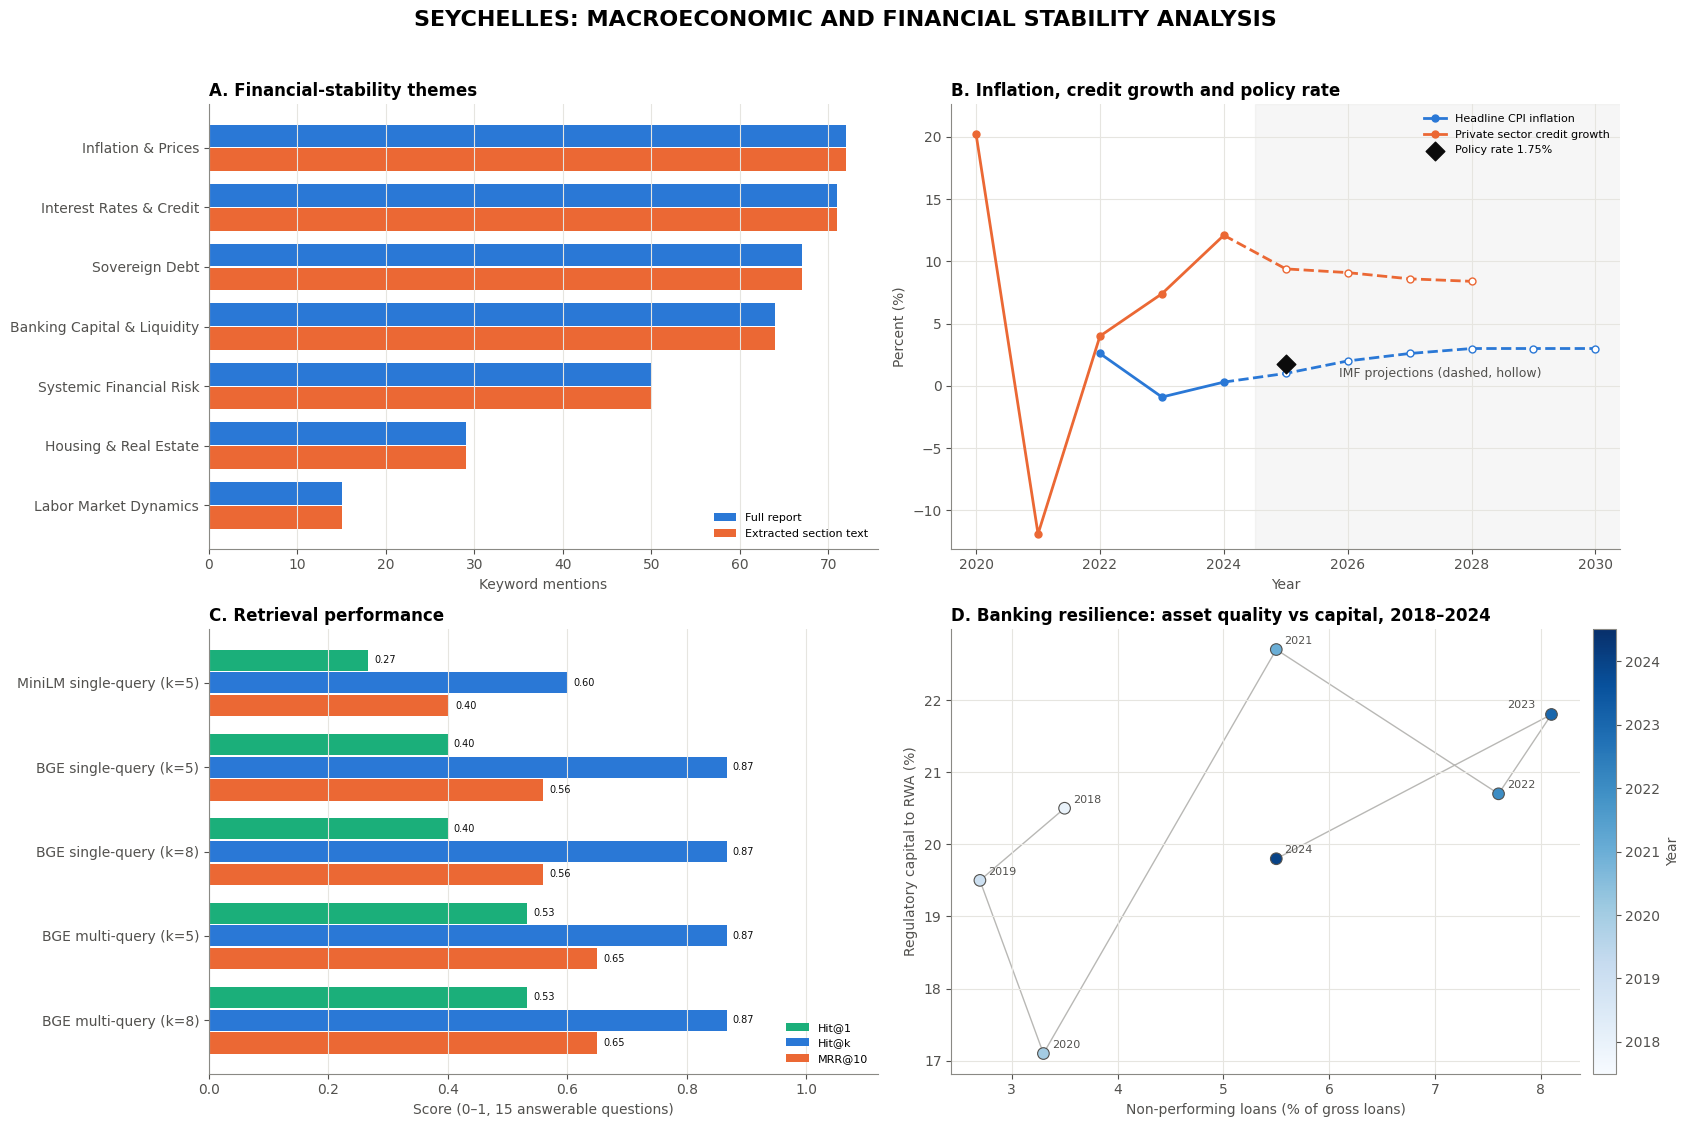

In [113]:
fig, axes = plt.subplots(2, 2, figsize=(17, 11))

plot_themes(axes[0, 0])
plot_inflation_rates(axes[0, 1])
plot_retrieval(axes[1, 0])
plot_banking(axes[1, 1], fig)

fig.suptitle(
    "SEYCHELLES: MACROECONOMIC AND FINANCIAL STABILITY ANALYSIS",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "seychelles_dashboard.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### 4.4 Macroeconomic Outlook and Fiscal Developments

In addition to the financial stability charts, I create four time-series visualisations to examine Seychelles' broader macroeconomic and fiscal performance.

The charts focus on the following indicators:

- **E. Real GDP Growth:** Shows the annual changes in real economic output and highlights the country's projected growth path.
- **F. Central Government Debt:** Illustrates changes in government debt as a percentage of GDP, helping assess the country's public debt position.
- **G. Current Account Balance:** Shows the current account balance as a percentage of GDP and helps identify changes in Seychelles' external position.
- **H. Primary Fiscal Balance:** Displays the government's primary fiscal balance as a percentage of GDP, providing insight into fiscal performance before interest payments.

Historical values are displayed using solid lines, while projected values are shown using dashed lines and hollow markers. This distinction makes it easier to separate observed economic developments from the IMF's outlook.

All four charts follow the same visual style, with consistent colours, labelled axes, and clearly stated measurement units. The figures are arranged in a 2-by-2 layout and saved as a high-resolution PNG image at 300 DPI.

Together, these visualisations provide a broader picture of Seychelles' economic growth, public debt, external balance, and fiscal position.

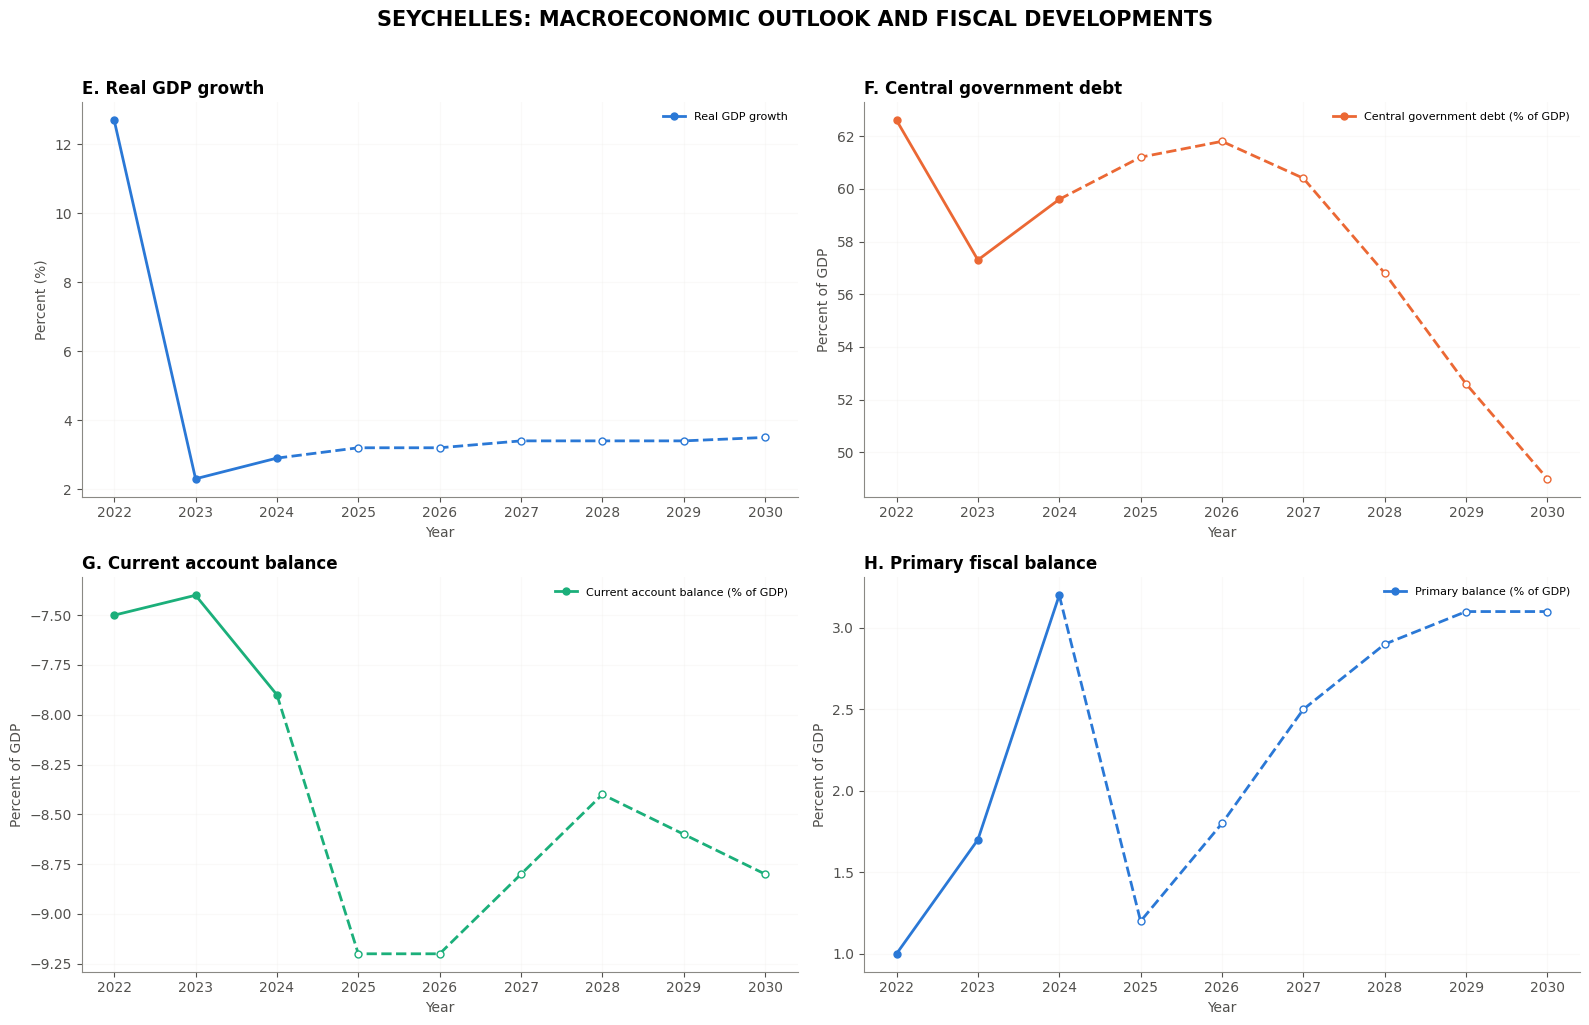

In [114]:
def plot_macro_series(ax, series_name, color, title, ylabel):
    d = long_df[long_df.series == series_name].sort_values("year")

    if d.empty:
        ax.set_title(title + " — no data")
        return

    draw_series(ax, series_name, color, series_name)

    ax.set_title(title, loc="left")
    ax.set_xlabel("Year")
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)


fig, axes = plt.subplots(2, 2, figsize=(16, 10))

plot_macro_series(
    axes[0, 0], S_GDP, BLUE,
    "E. Real GDP growth", "Percent (%)"
)

plot_macro_series(
    axes[0, 1], S_DEBT, ORANGE,
    "F. Central government debt", "Percent of GDP"
)

plot_macro_series(
    axes[1, 0], S_CA, AQUA,
    "G. Current account balance", "Percent of GDP"
)

plot_macro_series(
    axes[1, 1], S_PRIMARY, BLUE,
    "H. Primary fiscal balance", "Percent of GDP"
)

fig.suptitle(
    "SEYCHELLES: MACROECONOMIC OUTLOOK AND FISCAL DEVELOPMENTS",
    fontsize=15,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "seychelles_macro_dashboard.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [115]:
print("Dashboard files saved:")
print(os.path.join(OUT_DIR, "seychelles_dashboard.png"))
print(os.path.join(OUT_DIR, "seychelles_macro_dashboard.png"))

Dashboard files saved:
/content/drive/MyDrive/imf_outputs/seychelles_dashboard.png
/content/drive/MyDrive/imf_outputs/seychelles_macro_dashboard.png


### 4.5 The Interactive Dashboard (300 DPI)

The final dashboard brings together the main findings from the Seychelles IMF report, including macroeconomic indicators, financial stability themes, banking-sector developments, and RAG retrieval performance.

At the top of the dashboard, I include a summary section that is generated dynamically from the analysis results rather than entered manually.

The first summary line uses the extracted values from `seychelles_indicators.json`. If an indicator is missing or unavailable, it is displayed as **"Not reported"** instead of showing the fallback value of `-1.0`.

The second summary line is calculated from the extracted time-series data and model evaluation results. This allows the dashboard to highlight important economic trends and summarise the performance of the retrieval methods.

The charts and summary are generated directly from the underlying data. Therefore, if the extracted indicators, time series, or evaluation results change, the dashboard updates accordingly when the notebook is rerun.

The final dashboard is saved as a high-resolution image at 300 DPI, making it suitable for inclusion in the project report and presentation.

In [116]:
def fmt(key, label):
    v = indicators[key]
    per = (raw_indicators.get(key) or {}).get("period")

    return (
        f"{label}: not reported"
        if v == MISSING_VALUE
        else f"{label}: {v:g}%" + (f" ({per})" if per else "")
    )


kpi_line = "   |   ".join([
    fmt("gdp_growth_forecast_pct", "GDP growth (proj.)"),
    fmt("headline_inflation_rate_pct", "Inflation"),
    fmt("central_bank_policy_rate_pct", "Policy rate"),
    fmt("non_performing_loan_ratio", "NPL ratio"),
    fmt("unemployment_rate_pct", "Unemployment"),
    fmt("tier_1_capital_ratio", "Tier 1 capital")
])

print(kpi_line)

GDP growth (proj.): 3.2% (2025)   |   Inflation: -0.04% (March 2025)   |   Policy rate: 1.75% (Q2 2025)   |   NPL ratio: 5.5% (December 2024)   |   Unemployment: 2% (Q4 2024)   |   Tier 1 capital: 14.1% (2024)


In [117]:
infl_proj = wide.set_index("year").loc[REPORT_YEAR, S_INFL]
cap_s = wide.set_index("year")[S_CAP].dropna()
npl_s = wide.set_index("year")[S_NPL].dropna()
mq_gain = (rag_long.groupby("condition").completeness.mean()).round(2).to_dict()

insight_line = (f"Real policy rate ≈ {indicators['central_bank_policy_rate_pct'] - infl_proj:+.1f} pp vs projected "
                f"{REPORT_YEAR} inflation ({infl_proj:g}%)  •  Capital ratio {cap_s.iloc[-1]:g}% "
                f"(peak {cap_s.max():g}% in {cap_s.idxmax()}), NPLs {npl_s.iloc[-1]:g}% (low {npl_s.min():g}% in {npl_s.idxmin()})"
                f"  •  Multi-Query RAG completeness {mq_gain.get('multi')} vs {mq_gain.get('single')} (single)")
print(insight_line)

Real policy rate ≈ +0.8 pp vs projected 2025 inflation (1%)  •  Capital ratio 19.8% (peak 22.7% in 2021), NPLs 5.5% (low 2.7% in 2019)  •  Multi-Query RAG completeness 5.0 vs 4.33 (single)


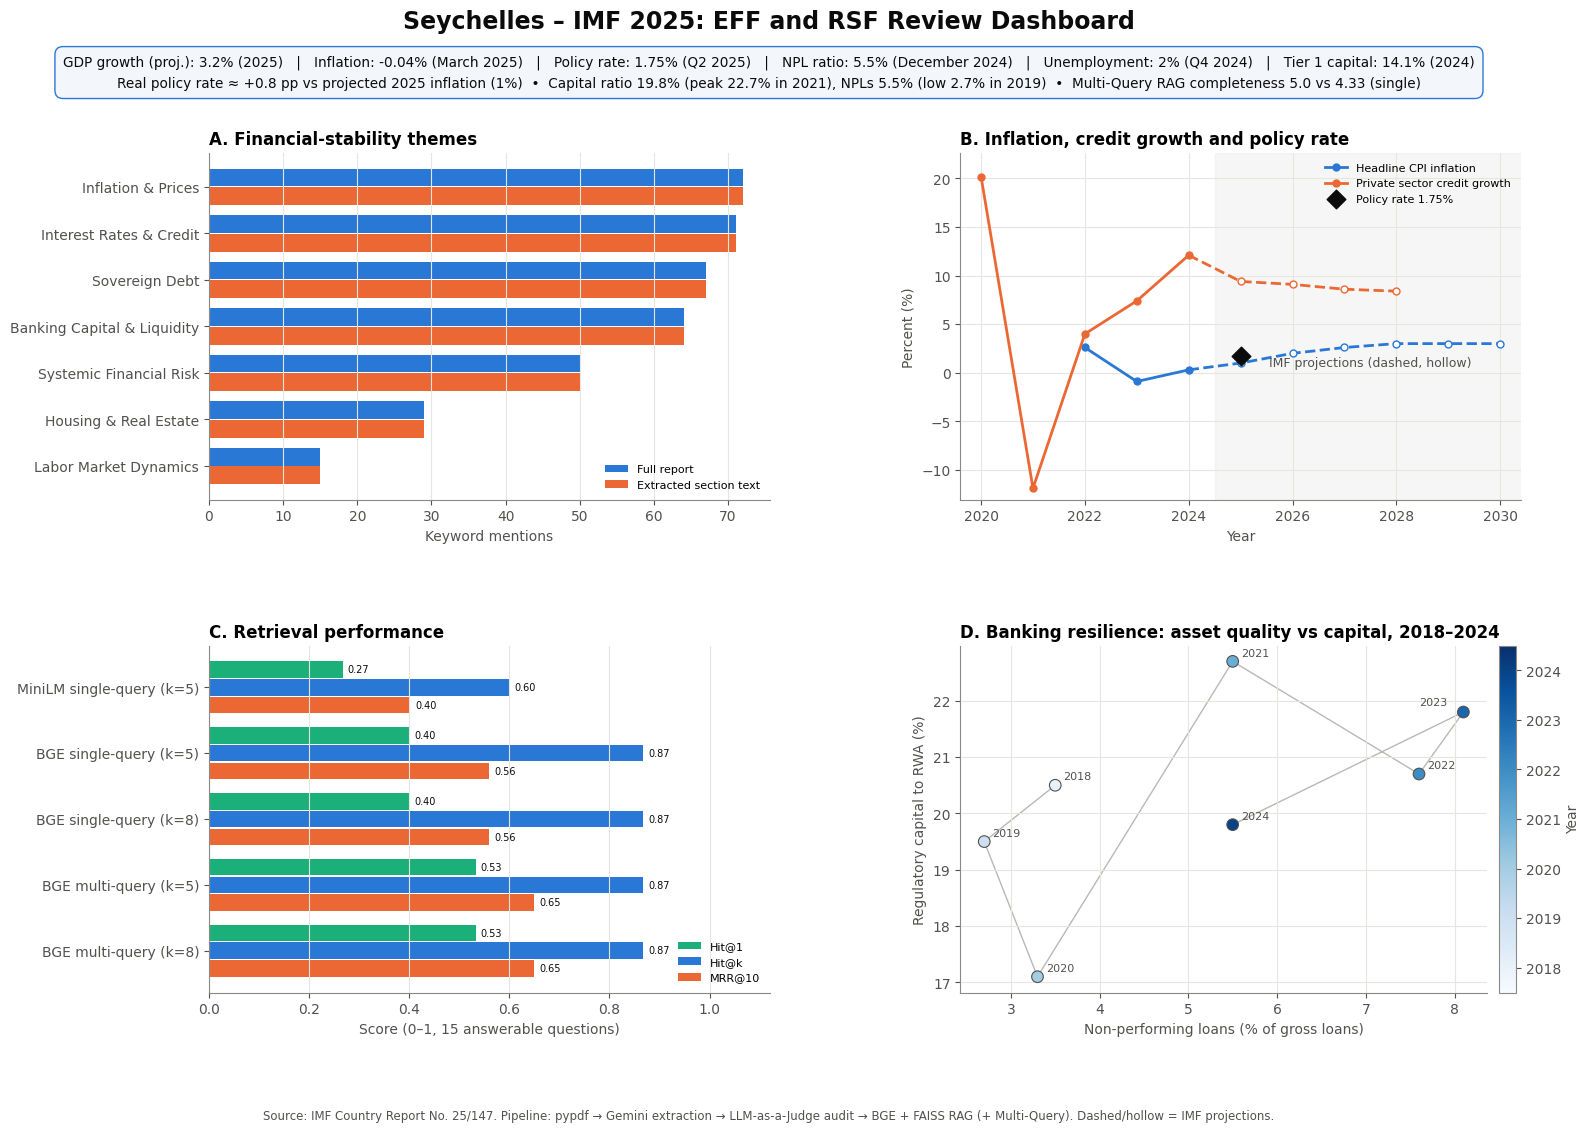

In [118]:
fig = plt.figure(figsize=(16, 11.5))
gs = fig.add_gridspec(2, 2, top=0.85, bottom=0.12, left=0.15, right=0.97,
                      hspace=0.42, wspace=0.34)

plot_themes(fig.add_subplot(gs[0, 0]))
plot_inflation_rates(fig.add_subplot(gs[0, 1]))
plot_retrieval(fig.add_subplot(gs[1, 0]))
plot_banking(fig.add_subplot(gs[1, 1]), fig)

fig.text(0.5, 0.975,
         f"{COUNTRY} – IMF {REPORT_YEAR}: EFF and RSF Review Dashboard",
         ha="center", va="top", fontsize=17, fontweight="bold", color=INK)

fig.text(0.5, 0.935, kpi_line + "\n" + insight_line,
         ha="center", va="top", fontsize=9.8, color=INK,
         linespacing=1.6,
         bbox=dict(boxstyle="round,pad=0.6", facecolor="#f3f6fb",
                   edgecolor=BLUE, lw=1))

fig.text(0.5, 0.01,
         f"Source: IMF Country Report No. {REPORT_NO}. Pipeline: pypdf → Gemini extraction → "
         "LLM-as-a-Judge audit → BGE + FAISS RAG (+ Multi-Query). Dashed/hollow = IMF projections.",
         ha="center", fontsize=8.5, color=INK_SOFT)

DASHBOARD_PATH = os.path.join(FIG_DIR, "seychelles_dashboard.png")
fig.savefig(DASHBOARD_PATH, dpi=300, facecolor="white", bbox_inches="tight")
plt.show()

In [119]:
img = Image.open(DASHBOARD_PATH)
dpi = img.info.get("dpi", (0, 0))
assert round(dpi[0]) >= 300, "dashboard must be saved at >= 300 dpi"
print(f"{DASHBOARD_PATH}: {img.size[0]}x{img.size[1]} px at {round(dpi[0])} dpi")

/content/drive/MyDrive/imf_outputs/figures/seychelles_dashboard.png: 4768x3396 px at 300 dpi


### 4.6 What the Dashboard Shows and What It Means for Policy

**A – Financial stability themes.** The theme analysis identifies how frequently the IMF report discusses topics such as inflation and prices, interest rates and credit, banking capital and liquidity, sovereign debt, housing, labour-market dynamics, and systemic financial risk. These mention counts help identify the report's main areas of focus. However, a higher number of mentions does not necessarily mean that a particular risk is more severe. The results should be interpreted alongside the report's actual discussion and recommendations.

**What it means for policy:** Seychelles needs to maintain price stability while monitoring financial-sector risks and its exposure to external economic shocks.

**B – Inflation, credit growth and monetary policy.** Headline inflation was 1.7% in December 2024, while the Central Bank of Seychelles maintained its Monetary Policy Rate at 1.75% from March 2024. Private-sector credit growth increased to 12.1% in 2024, compared with 7.4% in 2023. These developments show relatively low inflation alongside faster credit expansion.

**What it means for policy:** Monetary policy needs to balance price stability with developments in credit and domestic demand. Continued monitoring of credit growth is important to identify potential financial vulnerabilities.

**C – RAG retrieval performance.** The retrieval evaluation compares the performance of the embedding models and the Multi-Query approach using Hit@1, Hit@k and MRR@10. These measures show how effectively each method retrieves relevant passages from the Seychelles IMF report. The results help identify which retrieval configuration provides the strongest evidence for answering questions.

**What it means for the analysis:** Better retrieval can improve the reliability of AI-generated answers, but retrieval scores alone do not guarantee factual accuracy. The answers must also be checked for completeness, evidence and correct citations.

**D – Banking-sector resilience.** The NPL ratio declined from 8.1% in 2023 to 5.5% in December 2024. This indicates an improvement in reported loan quality. The banking-sector analysis should also consider capital adequacy and liquidity, using the exact measures reported in the IMF tables.

**What it means for policy:** Continued supervision of banks, monitoring of credit quality and adequate capital and liquidity buffers are important for maintaining financial stability. The NPL improvement is encouraging, but it does not remove the need to monitor emerging risks.

**E – Economic growth.** Real GDP growth was estimated at 2.9% in 2024, with growth projected to reach 3.2% in 2025. Tourism remains an important contributor to economic activity, although slower growth in tourism arrivals and lower spending per visitor present challenges.

**F – Public debt.** Public and publicly guaranteed debt stood at 59.6% of GDP in 2024. Fiscal discipline and effective public debt management remain important for maintaining confidence and protecting the government's ability to respond to future shocks.

**G – External position.** The current account deficit widened to 7.9% of GDP in 2024. Seychelles is exposed to external developments through tourism, imports, international trade and foreign investment. International reserves were approximately US$774 million at the end of 2024, equivalent to 3.8 months of imports.

**H – Fiscal balance.** The primary fiscal surplus was 3.2% of GDP in 2024. Maintaining a sustainable fiscal position is important, particularly given the country's exposure to economic shocks and climate-related risks.

**Overall assessment.** Seychelles demonstrated positive economic growth, low headline inflation, improving bank asset quality and a primary fiscal surplus in 2024. However, important vulnerabilities remain, including dependence on tourism, a widening current account deficit, public debt, and exposure to external and climate-related shocks.

The main policy message is to preserve macroeconomic stability, maintain sound public finances, strengthen financial-sector resilience and continue building protection against external shocks. Economic diversification and climate resilience are also important for supporting sustainable long-term growth.

### 4.6 Additional Visualisation: LLM Judge Evaluation Scores

This figure compares the evaluation scores assigned by the LLM judge to the executive and section summaries from Task 1 and the RAG-generated answers from Task 3. It also compares the performance of standard retrieval with the Multi-Query RAG approach.

For each evaluation category, the bar represents the average judge score, while the black marker indicates the lowest individual score. Showing both measurements provides a better understanding of overall performance and highlights cases where an individual response received a weaker evaluation.

Average scores alone may not reveal differences between the methods, particularly when most responses receive high scores. The minimum score therefore provides additional information about the weakest-performing responses.

If most scores are close to 5 out of 5, this may indicate that the judge is not sufficiently sensitive to distinguish between answers of different quality. Therefore, the scores should be interpreted as an additional evaluation measure rather than definitive proof that every generated answer is accurate or complete.

Overall, this visualisation helps assess the consistency of the LLM-generated summaries and RAG answers while identifying potential limitations in the automated evaluation process.

In [120]:
def plot_judge(ax, df, group_col, colors, title):
    agg = df.groupby([group_col, "metric"]).score.agg(["mean", "min"]).reset_index()
    labels = agg[group_col] + " · " + agg["metric"].str.replace("_", " ")
    y = np.arange(len(agg))[::-1]
    ax.barh(y, agg["mean"], color=[colors[g] for g in agg[group_col]], height=0.55)
    ax.scatter(agg["min"], y, color=INK, marker="|", s=250, lw=2, zorder=5)
    for yi, m in zip(y, agg["mean"]):
        ax.text(m + 0.08, yi, f"{m:.2f}", va="center", fontsize=9)
    ax.set_yticks(y, labels)
    ax.set_xlim(0, 5.7)
    ax.set_xlabel("Judge score (1 = poor, 5 = excellent); tick = lowest single score")
    ax.set_title(title, loc="left")
    ax.grid(axis="y", visible=False)

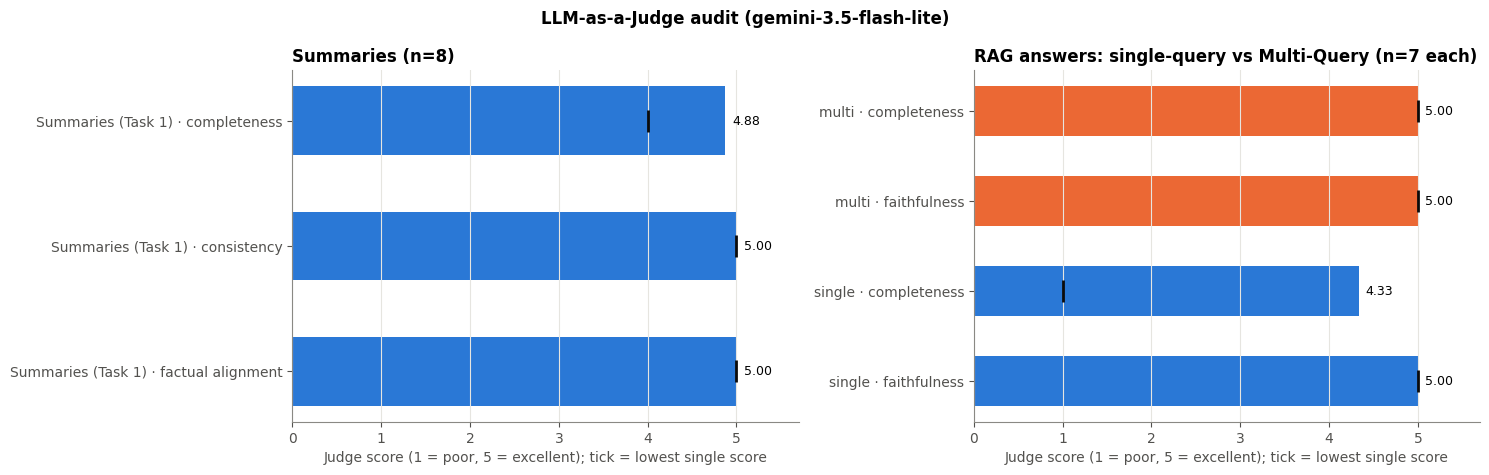

In [121]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4.8))

plot_judge(
    a1, summ_long, "stage",
    {"Summaries (Task 1)": BLUE},
    f"Summaries (n={len(judge_df)})"
)

plot_judge(
    a2, rag_scores, "condition",
    {"single": BLUE, "multi": ORANGE},
    f"RAG answers: single-query vs Multi-Query (n={len(EVAL_SET)} each)"
)

fig.suptitle(
    f"LLM-as-a-Judge audit ({', '.join(sorted(set(judge_df.judge_model)))})",
    fontweight="bold"
)

plt.tight_layout()

JUDGE_FIG_PATH = os.path.join(FIG_DIR, "seychelles_judge_diagnostics.png")
fig.savefig(JUDGE_FIG_PATH, dpi=300, facecolor="white", bbox_inches="tight")
plt.show()

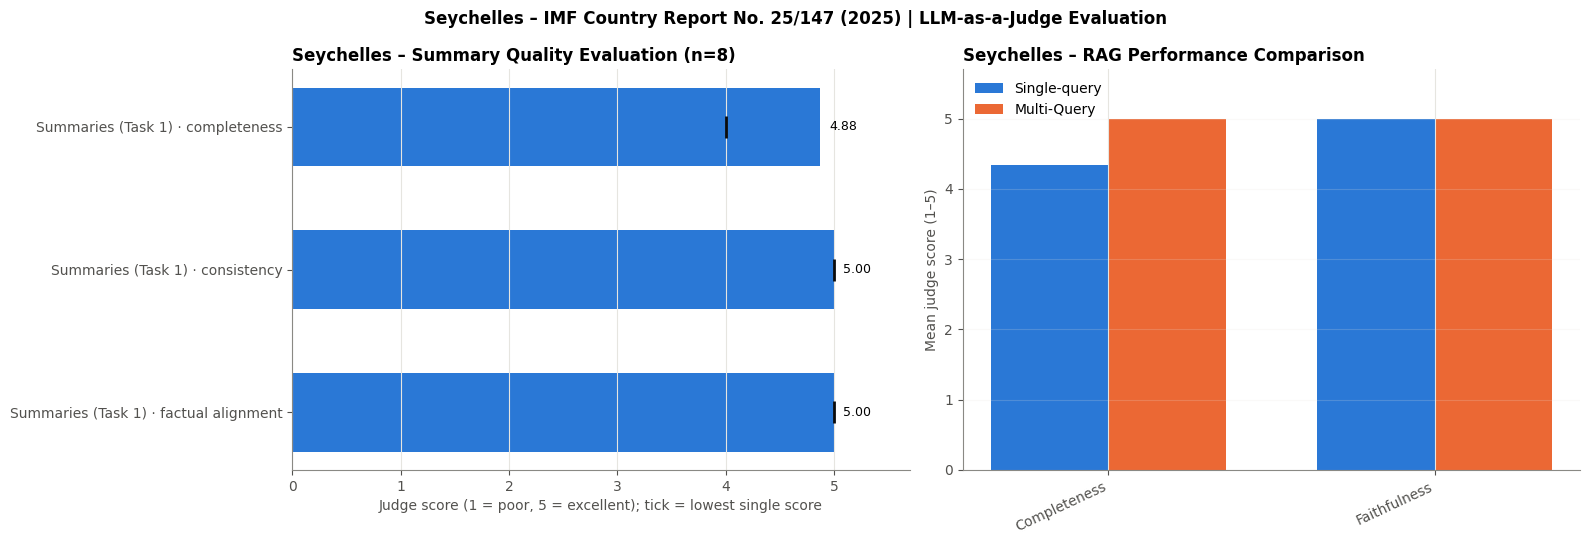

In [122]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 5.5))

# Chart 1: Seychelles IMF report summary evaluation
plot_judge(
    a1,
    summ_long,
    "stage",
    {"Summaries (Task 1)": BLUE},
    f"Seychelles – Summary Quality Evaluation (n={len(judge_df)})"
)

# Chart 2: Seychelles RAG evaluation
rag_agg = (
    rag_scores.groupby(["condition", "metric"])["score"]
    .mean()
    .unstack("condition")
)

rag_agg = rag_agg.reindex(columns=["single", "multi"])

x = np.arange(len(rag_agg))
width = 0.36

a2.bar(
    x - width / 2,
    rag_agg["single"],
    width,
    label="Single-query",
    color=BLUE
)

a2.bar(
    x + width / 2,
    rag_agg["multi"],
    width,
    label="Multi-Query",
    color=ORANGE
)

a2.set_xticks(x)
a2.set_xticklabels(
    rag_agg.index.str.replace("_", " ").str.title(),
    rotation=25,
    ha="right"
)

a2.set_ylim(0, 5.7)
a2.set_ylabel("Mean judge score (1–5)")
a2.set_title("Seychelles – RAG Performance Comparison", loc="left")
a2.legend(frameon=False)
a2.grid(axis="y", alpha=0.2)

fig.suptitle(
    f"Seychelles – IMF Country Report No. {REPORT_NO} "
    f"({REPORT_YEAR}) | LLM-as-a-Judge Evaluation",
    fontweight="bold"
)

plt.tight_layout()

JUDGE_FIG_PATH = os.path.join(
    FIG_DIR,
    "seychelles_judge_diagnostics.png"
)

fig.savefig(
    JUDGE_FIG_PATH,
    dpi=300,
    facecolor="white",
    bbox_inches="tight"
)

plt.show()

## Unit Tests

I include a set of unit tests to check that the helper functions used throughout the Seychelles analysis work correctly. These tests focus on common formatting and validation issues that can affect data extraction, citation checking, and RAG evaluation.

The tests cover several situations encountered during the development of the notebook, including:

- **Numeric formatting:** Ensuring that values such as `28.0` and `28` are treated as equivalent when comparing extracted figures.
- **Citation formatting:** Checking that references containing multiple chunk identifiers, such as `[chunks 12, 23]`, are correctly recognised and validated.
- **JSON parsing:** Testing whether the extraction functions can handle JSON responses wrapped in Markdown code fences.
- **Text normalisation:** Confirming that supporting sentences are still matched when PDF extraction introduces line breaks, punctuation changes, or breaks after dash characters, such as in the NPL discussion.

These tests run locally in Python and do not require Gemini API calls. They help identify errors in the validation functions before those functions are used on the full Seychelles report.

Passing the unit tests does not guarantee that every extracted result is factually correct. It confirms that the helper functions behave as expected for the tested cases.

In [123]:
# number matching
assert re.search(num_regex("28"), "debt 28.0 percent") and not re.search(num_regex("27"), "debt 27.2")
assert not re.search(num_regex("2.4"), "12.4") and re.search(num_regex("-1.9"), "balance -1.9")
assert check_numbers("Growth was 4.3 percent in 2025.", "at 4.3 percent")["support_rate"] == 1.0
assert check_numbers("Growth was 5.1 percent.", "at 4.3 percent")["unsupported_numbers"] == ["5.1"]

# JSON parsing
assert parse_json('```json\n{"a": 1}\n```') == {"a": 1}
assert parse_json('Here you go: [1, 2]') == [1, 2]
assert to_float("3.8%") == 3.8 and to_float(None) is None and to_float("n/a") is None

print("number + JSON tests passed")

number + JSON tests passed


In [124]:
# citations and answer status
assert cited_ids("See [chunk 12] and [chunks 3, 4].") == {12, 3, 4}
assert cited_ids("[chunk 118, chunk 38]") == {118, 38}
assert answer_status({"answer": "X [chunk 9]", "unit_ids": [1, 2]}) == "citation error [9]"
assert answer_status({"answer": REFUSAL, "unit_ids": [1]}) == "refused"

# quote matching ignores line breaks / dashes
assert quote_support(
    "NPLs decreased from 8.1 percent in 2023 to 5.5 percent in December 2024"
) >= 0.8

# schema validation rejects wrong types
bad = {**indicators, "tier_1_capital_ratio": "n/a"}

try:
    validate_schema(bad)
    raise AssertionError("schema accepted a string")
except AssertionError as e:
    assert "must be float" in str(e)

print("citation + quote + schema tests passed")

citation + quote + schema tests passed


In [126]:
# chunking: every chunk within budget, and overlap is made of whole units from the previous chunk
assert all(c["n_tokens"] <= CHUNK_TOKENS + CHUNK_OVERLAP + 20 for c in chunks)
starts_with_overlap = sum(chunks[i]["text"][:40] in chunks[i - 1]["text"] for i in range(1, len(chunks)))
print(f"chunks starting with text from the previous chunk (overlap): {starts_with_overlap}/{len(chunks) - 1}")
assert "".join(sections.values()) == full_text
print("chunking + coverage tests passed")

chunks starting with text from the previous chunk (overlap): 238/278
chunking + coverage tests passed


## Reproducibility and Execution Record

To make the Seychelles analysis easier to reproduce, I include a final record of the notebook execution. This captures the versions of the main Python libraries, the date and time when the run was completed, and the number of LLM responses retrieved from the cache compared with those generated through new API requests.

Recording the software versions helps identify the environment used for the analysis, while the execution timestamp provides a reference for each run. The cache statistics also show how efficiently the notebook reuses previously generated results.

When the notebook is executed for the first time, some API requests may be required to generate the outputs. On subsequent runs, unchanged requests can reuse their cached responses, reducing execution time, API usage, and unnecessary costs.

The reproducibility record therefore provides a useful summary of the execution environment and helps demonstrate that the analysis can be repeated consistently. Actual cache counts and execution details are generated by the notebook rather than entered manually.

In [127]:
import platform, importlib.metadata as im
def version_of(pkg):
    try:
        return im.version(pkg)
    except im.PackageNotFoundError:
        return "not found"

versions = {p: version_of(p) for p in ["pypdf", "tiktoken", "google-genai", "sentence-transformers", "faiss-cpu",
                                        "pandas", "matplotlib", "numpy"]}
print("Python", platform.python_version(), "|", versions)
print("LLM answers this run:", dict(CALL_STATS))
print("Run finished:", time.strftime("%Y-%m-%d %H:%M"))

Python 3.13.18 | {'pypdf': '7.0.0', 'tiktoken': '0.14.0', 'google-genai': '2.12.1', 'sentence-transformers': '5.7.0', 'faiss-cpu': '1.15.1', 'pandas': '2.2.3', 'matplotlib': '3.10.0', 'numpy': '2.4.6'}
LLM answers this run: {'api calls': 45, 'from cache': 2}
Run finished: 2026-11-09 01:09


In [128]:
models_used = Counter(v["model"] for v in llm_cache.values())
findings = {
    "report": f"IMF Country Report No. {REPORT_NO}",
    "cleaning_pct_removed": round(100 - 100 * len(full_text) / raw_chars, 1),
    "chunks": len(chunks), "retrieval_units": len(rag_units),
    "summary_words_max": max(r["words"] for r in section_results.values()),
    "judge_means": judge_df[SCORE_COLS].mean().round(2).to_dict(),
    "numeric_support_exec_summary": grounding["EXECUTIVE SUMMARY"]["support_rate"],
    "indicators": indicators, "fallbacks": list(fallback_log),
    "trend_series_verified": int(trend_check_df.values_found.sum()), "trend_series": len(trends),
    "minilm_text_unseen_pct": float(trunc_df.loc["MiniLM", "text_unseen_pct"]),
    "cleaning_kept_text_identical_pages": f"{sum(identical)}/{len(pages)}",
    "retrieval_questions": len(ANSWERABLE),
    "citation_repairs": {c: [q for q, r in rs.items() if r.get("repaired")] for c, rs in rag_results.items()},
    "llm_calls_this_run": dict(CALL_STATS),
    "retrieval": retrieval_df.to_dict("records"),
    "rag_means": rag_long.groupby("condition")[["faithfulness", "completeness"]].mean().round(2).to_dict("index"),
    "rag_status": rag_long.groupby(["condition", "status"]).size().to_dict(),
    "models_used": dict(models_used),
}
save_json({k: (str(v) if isinstance(v, dict) and any(isinstance(x, tuple) for x in v) else v)
           for k, v in findings.items()}, os.path.join(OUT_DIR, "findings.json"))
for k, v in findings.items():
    print(f"{k}: {v}")

report: IMF Country Report No. 25/147
cleaning_pct_removed: 6.1
chunks: 279
retrieval_units: 279
summary_words_max: 86
judge_means: {'consistency': 5.0, 'completeness': 4.88, 'factual_alignment': 5.0}
numeric_support_exec_summary: 1.0
indicators: {'country_name': 'Seychelles', 'gdp_growth_forecast_pct': 3.2, 'headline_inflation_rate_pct': -0.04, 'central_bank_policy_rate_pct': 1.75, 'non_performing_loan_ratio': 5.5, 'unemployment_rate_pct': 2.0, 'tier_1_capital_ratio': 14.1}
fallbacks: []
trend_series_verified: 3
trend_series: 8
minilm_text_unseen_pct: 18.7
cleaning_kept_text_identical_pages: 126/126
retrieval_questions: 15
citation_repairs: {'single': [], 'multi': []}
llm_calls_this_run: {'api calls': 45, 'from cache': 2}
retrieval: [{'config': 'MiniLM single-query', 'hit@1': 0.267, 'hit@k': 0.6, 'mrr@10': 0.402, 'k': 5, 'n': 15}, {'config': 'BGE single-query', 'hit@1': 0.4, 'hit@k': 0.867, 'mrr@10': 0.56, 'k': 5, 'n': 15}, {'config': 'BGE single-query', 'hit@1': 0.4, 'hit@k': 0.867, 

In [129]:
print("Files in", OUT_DIR)
for root, _, files in os.walk(OUT_DIR):
    for f in sorted(files):
        if not f.endswith(".tmp"):
            p = os.path.join(root, f)
            print(f"  {os.path.relpath(p, OUT_DIR):45s} {os.path.getsize(p) / 1024:8.1f} KB")

Files in /content/drive/MyDrive/imf_outputs
  chunks.json                                      412.3 KB
  cleaned_text.txt                                 341.7 KB
  findings.json                                      2.0 KB
  indicators.json                                    0.2 KB
  sections.json                                    345.0 KB
  seychelles_dashboard.png                         698.7 KB
  seychelles_macro_dashboard.png                   482.3 KB
  task1_summaries.json                              21.9 KB
  task2_outputs.json                                19.0 KB
  task2_thematic_distribution.json                   1.6 KB
  task3_rag.json                                   175.7 KB
  task4_long_format.json                             7.4 KB
  cache/emb_BGE_cf77bb424008e073.npy               418.6 KB
  cache/emb_MiniLM_514a5c3f15fedfb9.npy            418.6 KB
  cache/faiss_BGE_cf77bb424008e073.index           418.5 KB
  cache/faiss_MiniLM_514a5c3f15fedfb9.index        418.5